# Mikołaj: Causal Tracing na gpt2-xl (Część I, pkt 1–2)

Zakres (3 pkt), szczegóły w [mikolaj.md](mikolaj.md) i [instrukcji](../Zadanie_4.md):

1. **I.1–3 [1.5 pkt]**: notatki z surveyu KE (definicja zadania, metryki), ROME / Causal Tracing, pyvene 101 (+ notebook #1).
2. **Plan pkt 1**: odtworzenie notebooka #2 (`Causal_Tracing.ipynb`): Space Needle → Seattle na gpt2-xl.
3. **Plan pkt 2 [1.5 pkt]**: 5 własnych faktów, zaszumiony **tylko podmiot**, wykresy `block_output` / `mlp_activation` / `attention_output`.
4. Odpowiedzi na pytania pomocnicze.

**Zasada:** cały kod jest w `../utils/tracing/` (pętla, szum, analiza, wykresy). Tu tylko wywołania i wnioski.
Wyniki (CSV/JSON) trafiają do `artifacts/mikolaj/` i są cache'owane. **Dominik czyta je do porównania**, więc nie zmieniaj nazw (`name=`) po zapisaniu. Końcowe wykresy: `figures/*.png`.

Kolejność notebooka: 1) teoria causal tracingu, 2) pyvene, 3) Space Needle, 4) własne fakty, 5) analiza i pytania pomocnicze, 6) survey KE.

## 0. Środowisko

In [2]:
import sys

sys.path.insert(0, "..")

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_formats = ['retina']

In [3]:
import pandas as pd
import pyvene as pv
import torch
import transformers

from utils.infra import artifacts_dir, get_device, set_seed

set_seed(42)
OUT = artifacts_dir("mikolaj")
FIGURES = "figures"
device = get_device()
print(f"torch {torch.__version__}, transformers {transformers.__version__}, device: {device}")
print(f"wyniki: {OUT}")

nnsight is not detected. Please install via 'pip install nnsight' for nnsight backend.
torch 2.14.1, transformers 5.19.0, device: mps
wyniki: /Users/macham1/Uni/2sem/NLP/04/artifacts/mikolaj


## 1. Teoria: analiza mediacji i Causal Tracing (I.2: ROME)

### Analiza mediacji

Analiza mediacji (statystyka, nauki społeczne, medycyna) pyta nie tylko *czy* X wpływa na Y, ale *którędy*. Model ma trzy zmienne:

- **X**: zmienna niezależna (przyczyna),
- **M**: mediator, czyli zmienna pośrednia, przez którą może płynąć wpływ,
- **Y**: zmienna zależna (wynik).

Wpływ X na Y dzieli się na:

- **efekt całkowity (TE)**: o ile zmienia się Y, gdy zmienimy X,
- **efekt pośredni (IE)**: część TE, która płynie przez M,
- **efekt bezpośredni (DE)**: część TE, która M omija.

Efekt pośredni mierzymy **interwencją**: zmieniamy X, ale mediator M ustawiamy na wartość, jaką miałby przy oryginalnym X. Jeśli Y wraca do oryginału, cały wpływ płynął przez M.

### Przeniesienie na transformer

| Analiza mediacji | Model językowy (ROME) |
|---|---|
| X | osadzenia tokenów wejścia, w szczególności **tokenów podmiotu** („The Space Needle”) |
| M | **stan ukryty** $h_i^{(l)}$ na pozycji $i$ w warstwie $l$ (lub wyjście MLP / atencji w tej warstwie) |
| Y | prawdopodobieństwo poprawnej odpowiedzi $P(o)$, np. $P(\text{" Seattle"})$ |

Mediatorów jest bardzo dużo (każda warstwa × każda pozycja × każdy komponent), a pytanie brzmi: **przez które z nich płynie wiedza o fakcie?**

### Causal Tracing: trzy przebiegi

1. **Czysty** (clean): prompt bez zmian, zapisujemy wszystkie stany $h_i^{(l)}$ i $P(o)$.
2. **Zaszumiony** (corrupted): do osadzeń tokenów podmiotu dodajemy szum $\varepsilon \sim \mathcal{N}(0, \nu^2)$, gdzie $\nu = 3\sigma$ (σ to odchylenie std osadzeń). Model „nie wie”, o jaki podmiot chodzi, więc $P_*(o)$ spada.
3. **Zaszumiony z przywróceniem** (corrupted-with-restoration): jak w 2, ale w **jednym** miejscu $(i, l)$ wstawiamy stan z przebiegu czystego. Mierzymy $P_{*,\,\text{clean } h_i^{(l)}}(o)$.

$$\text{TE} = P(o) - P_*(o) \qquad \text{IE}(h_i^{(l)}) = P_{*,\,\text{clean } h_i^{(l)}}(o) - P_*(o)$$

Duży IE oznacza, że ten stan sam wystarcza, żeby przywrócić fakt, więc niesie potrzebną informację. Wykres causal tracingu to mapa IE (albo samego $P$ po przywróceniu) dla wszystkich warstw × pozycji.

### Trzy komponenty (strumienie)

- **`block_output`**: wyjście całego bloku, czyli strumień rezydualny po warstwie $l$. Przywracamy jedną warstwę.
- **`mlp_activation`**: aktywacje MLP (po nieliniowości). Przywracamy **okno 10 kolejnych warstw**, bo pojedyncza warstwa MLP ma mały wkład, a fakt jest rozłożony na kilka warstw.
- **`attention_output`**: wyjście atencji, też okno 10 warstw.

### Co znalazł ROME (gpt2-xl)

- **Wczesne miejsce** (*early site*): **MLP w środkowych warstwach na ostatnim tokenie podmiotu** („le” w „Needle”). Tu model „wyciąga” wiedzę o podmiocie. Na tym ROME opiera edycję: MLP traktuje jako pamięć klucz → wartość i zmienia ją aktualizacją rzędu 1.
- **Późne miejsce** (*late site*): **atencja w późnych warstwach na ostatnim tokenie wejścia** przenosi informację z podmiotu tam, gdzie powstaje predykcja.
- `block_output` pokazuje oba miejsca, bo strumień rezydualny zawiera wszystko, co policzono do tej pory. Jasny obszar w późnych warstwach na ostatnim tokenie jest trywialny: ostatni stan ostatniego tokenu prawie wprost wyznacza predykcję.

### Dlaczego szum, a nie inny podmiot?

Szum niszczy informację o podmiocie, zachowując długość sekwencji i pozycje. Podmiana na inny podmiot (np. „Eiffel Tower”) wprowadziłaby **inny** fakt i mierzylibyśmy coś innego (przełączenie odpowiedzi, a nie jej utratę). Skala $3\sigma$ jest na tyle duża, że osadzenie przestaje przypominać oryginał, a jednocześnie nie wychodzi skrajnie poza rozkład, który model widział w treningu.

### Przykład liczbowy: Space Needle na gpt2-xl

Prompt: `The Space Needle is in downtown`, odpowiedź: `" Seattle"`, zaszumione tokeny podmiotu: `The`, ` Space`, ` Need`, `le` (szum $\nu = 0{,}1346$, jak w notebooku #2). Liczby z jednego uruchomienia (wybrane warstwy).

**Przebieg 1, czysty:** $P(\text{Seattle}) = 0{,}976$. Model zna fakt.

**Przebieg 2, zaszumiony:** $P_*(\text{Seattle}) = 0{,}033$. Top-5 po zaszumieniu: ` Los` 0,054, ` San` 0,036, ` Seattle` 0,033, ` Toronto` 0,026, ` Vancouver` 0,017. Model wie, że po „…is in downtown” pada nazwa miasta, ale nie wie już, *które* miasto.

$$\text{TE} = P(o) - P_*(o) = 0{,}976 - 0{,}033 = 0{,}943$$

TE (*total effect*, efekt całkowity) mówi, ile podmiot w ogóle znaczy dla odpowiedzi: bez informacji o podmiocie tracimy 0,943 prawdopodobieństwa.

**Przebieg 3, zaszumiony z przywróceniem** (`block_output`, jeden stan naraz; wartość = $P(\text{Seattle})$ po przywróceniu):

| token \ warstwa | 0 | 5 | 10 | 15 | 20 | 25 | 30 | 35 | 40 | 47 |
|---|---|---|---|---|---|---|---|---|---|---|
| The* | 0,040 | 0,042 | 0,034 | 0,034 | 0,034 | 0,034 | 0,034 | 0,034 | 0,034 | 0,033 |
| Space* | 0,038 | 0,034 | 0,037 | 0,042 | 0,038 | 0,038 | 0,040 | 0,040 | 0,038 | 0,033 |
| Need* | 0,026 | 0,032 | 0,032 | 0,031 | 0,032 | 0,031 | 0,032 | 0,033 | 0,033 | 0,033 |
| **le*** | 0,029 | 0,031 | 0,697 | **0,968** | 0,918 | 0,848 | 0,700 | 0,351 | 0,107 | 0,033 |
| is | 0,033 | 0,033 | 0,033 | 0,031 | 0,033 | 0,038 | 0,048 | 0,040 | 0,039 | 0,033 |
| in | 0,033 | 0,034 | 0,034 | 0,032 | 0,036 | 0,039 | 0,063 | 0,057 | 0,056 | 0,033 |
| **downtown** | 0,034 | 0,033 | 0,032 | 0,033 | 0,036 | 0,063 | 0,480 | 0,905 | 0,955 | **0,976** |

Ten sam tracing dla `mlp_activation` (okno 10 warstw MLP) na `le*`: warstwa 10: 0,058, **15: 0,838**, 20: 0,697, 25: 0,127, 30: 0,046. Na pozostałych tokenach ok. 0,03.

Odczyt:

- Przywrócenie **jednego wektora** `le*` w warstwie 15 daje $P = 0{,}968$, więc $\text{IE} = 0{,}968 - 0{,}033 = 0{,}935$, czyli ok. 99% TE. Ten stan niesie praktycznie cały fakt.
- `The*`, `Space*`, `Need*` nic nie dają. Atencja jest przyczynowa (token widzi tylko tokeny przed sobą), więc dopiero `le` „zna” cały podmiot „Space Needle”. Poza tym przywrócenie jednego tokenu zostawia pozostałe zaszumione.
- **Wczesne miejsce**: `le*`, warstwy ok. 10–25, wyraźnie w MLP (okno wokół 15). Tu model wydobywa wiedzę o podmiocie.
- **Późne miejsce**: `downtown` od ok. 30 warstwy. Informacja została już przeniesiona (atencją) z `le` na ostatni token.
- Po warstwie ok. 35 przywracanie `le` przestaje pomagać: późniejsze warstwy już nie czytają z tej pozycji, bo przeniesienie na `downtown` odbyło się wcześniej (na zaszumionym `le`).
- `downtown`, warstwa 47 = 0,976 = przebieg czysty. Jest to trywialne, bo ostatni stan ostatniego tokenu wprost wyznacza predykcję.

## 2. pyvene (I.3) i pierwszy tracing na małym gpt2

### pyvene w pigułce

[pyvene](https://github.com/stanfordnlp/pyvene) (Stanford NLP) to biblioteka do **interwencji** na stanach ukrytych modeli PyTorch / HuggingFace. Zamiast ręcznie pisać hooki, opisujemy interwencję deklaratywnie:

| Pojęcie | Co to jest |
|---|---|
| `RepresentationConfig(layer, component)` | **gdzie** interweniujemy: numer warstwy + komponent, np. `"block_output"`, `"mlp_activation"`, `"attention_output"`, `"block_input"` (dla warstwy 0 to osadzenia tokenów) |
| `IntervenableConfig(representations, intervention_types)` | lista miejsc + **jaki** typ interwencji w każdym z nich |
| `IntervenableModel(config, model)` | opakowanie modelu; podpina hooki tylko na czas przebiegu, model się nie zmienia |
| `intervenable(base, sources, unit_locations)` | przebieg: `base` to wejście, na którym liczymy wynik; `sources` to wejścia, z których bierzemy wartości; `unit_locations` to **pozycje tokenów** (`"sources->base": (pozycje w źródle, pozycje w bazie)`) |
| zwraca `(base_outputs, counterfactual_outputs)` | wyjście bez interwencji i z interwencją |

Typy interwencji:

- `VanillaIntervention`: **podmiana** (*interchange*), czyli wstaw wartość ze źródła w miejsce wartości z bazy,
- `ConstantSourceIntervention`: interwencja bez źródła (stała albo funkcja bazy, np. dodanie szumu),
- `CollectIntervention`: tylko **zbiera** aktywacje (używa tego notebook #3 do sondowania),
- `LowRankRotatedSpaceIntervention`: interwencja uczona w obróconej podprzestrzeni (DAS, notebook #3).

pyvene zna nazwy modułów dla popularnych architektur (GPT-2, GPT-NeoX/Pythia, Llama…), więc `"mlp_activation"` w warstwie 5 GPT-2 samo tłumaczy się na `transformer.h[5].mlp.act`.

### Notebook #1 (`Basic_Intervention.ipynb`): *interchange intervention*

Baza: `"The capital of Spain is"` (odpowiedź Madrid), źródło: `"The capital of Italy is"` (Rome). Dla każdej warstwy i pozycji podmieniamy wyjście MLP (albo wejście atencji) bazy na wartość ze źródła i patrzymy na $P(\text{Madrid})$ i $P(\text{Rome})$. Jeśli po podmianie jednego miejsca model mówi „Rome”, to miejsce niesie informację o kraju. To ta sama idea co causal tracing, tylko zamiast szumu i przywracania mamy **podmianę między dwoma wejściami** (*activation patching*).

### Causal tracing w języku pyvene

Tak to zapisuje `utils/tracing/interventions.py`:

1. **Szum**: `RepresentationConfig(0, "block_input")` + własna `NoiseIntervention` (`ConstantSourceIntervention`, bo nie potrzebuje źródła), `unit_locations` = pozycje podmiotu.
2. **Przywrócenie**: dodatkowo `RepresentationConfig(l, stream)` z `VanillaIntervention` dla każdej warstwy okna. **Źródłem jest to samo zdanie bez szumu**, czyli przebieg czysty, a pozycja w źródle = pozycja w bazie.
3. Jeden `IntervenableModel` na warstwę, pętla po pozycjach, z wyjścia liczymy $P(o)$ przez `score_fn`.

Najpierw sprawdzamy to na małym `gpt2` (12 warstw, sekundy zamiast minut), żeby zobaczyć API, zanim puścimy gpt2-xl.

In [4]:
from utils.infra import load_causal_lm
from utils.tracing import (
    compute_noise_level,
    find_token_positions,
    next_token_prob,
    restore_config,
    make_noise_intervention,
    streams_summary,
    tokenize,
    top_next_tokens,
    trace_all_streams,
)
from utils.tracing.plot import plot_trace_streams

small, small_tok = load_causal_lm("gpt2", device)
text = "The Space Needle is in downtown"
subject = find_token_positions(small_tok, text, "The Space Needle")
print(tokenize(small_tok, text), "-> podmiot:", subject)
top_next_tokens(small, small_tok, text, k=5)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

['The', ' Space', ' Need', 'le', ' is', ' in', ' downtown'] -> podmiot: [0, 1, 2, 3]


,token,prob
0,Seattle,0.080524
1,Los,0.040981
2,San,0.036334
3,Washington,0.034581
4,Houston,0.033872


### Anatomia bloku GPT-2: co znaczą `block_input`, `mlp_activation`, `attention_output`, `block_output`

Wejście każdego tokenu to wektor (768 liczb w gpt2, 1600 w gpt2-xl). Ten wektor płynie w górę przez wszystkie warstwy jako **strumień rezydualny** (*residual stream*). Można o nim myśleć jak o „notatniku tokenu”: każdy blok (warstwa) $l$ niczego nie wymazuje, tylko **dopisuje** dwie poprawki: z atencji i z MLP.

```
          token "le"                          (osobny strumień dla każdej pozycji)
              │
   osadzenie tokenu + osadzenie pozycji
              │
              ▼
   ┌─────────── blok l ────────────────────────────────────────┐
   │ x  ◄─ block_input (warstwa 0: osadzenia, tu dodajemy szum) │
   │ │                                                          │
   │ ├──► LayerNorm ─► ATENCJA (czyta inne pozycje) ─► attention_output
   │ │                                                    │     │
   │ x' = x + attention_output  ◄─────────────────────────┘     │
   │ │                                                          │
   │ ├──► LayerNorm ─► c_fc (768→3072) ─► GELU ─► mlp_activation│
   │ │                                       │                  │
   │ │                          c_proj (3072→768) ─► mlp_output │
   │ │                                       │                  │
   │ x'' = x' + mlp_output  ◄────────────────┘                  │
   │ │                                                          │
   │ x'' ─► block_output (= block_input warstwy l+1)            │
   └────────────────────────────────────────────────────────────┘
```

| Komponent | Co to jest | Rozmiar (gpt2 / gpt2-xl) |
|---|---|---|
| `block_input` | strumień rezydualny **wchodzący** do bloku; w warstwie 0 to osadzenie tokenu + pozycji | 768 / 1600 |
| `attention_output` | poprawka dodana przez atencję w tej warstwie; jedyne miejsce, gdzie informacja **przechodzi między pozycjami** | 768 / 1600 |
| `mlp_activation` | wnętrze MLP po nieliniowości GELU: „neurony” MLP, przed rzutowaniem z powrotem; MLP działa na jednym tokenie | 3072 / 6400 (4×) |
| `block_output` | strumień rezydualny **po** całym bloku: wszystko, co policzono do tej pory | 768 / 1600 |

Wniosek dla tracingu:

- przywrócenie `block_output` w warstwie $l$ przywraca **cały stan** tokenu (sumę wszystkich wcześniejszych wkładów), więc wystarcza **jedna warstwa**;
- przywrócenie `mlp_activation` lub `attention_output` przywraca **tylko wkład jednego podmodułu**, a reszta strumienia jest nadal zaszumiona. Pojedynczy wkład jest mały, a wiedza rozłożona na kilka warstw, dlatego ROME przywraca **okno 10 kolejnych warstw** naraz.

### Okno 10 warstw „wokół” warstwy $l$

`restore_window(l, window=10)` = warstwy od $l-5$ do $l+4$ (10 warstw), obcięte do zakresu modelu. Na wykresie punkt na osi X = $l$ to **środek** okna, a przywracamy jednocześnie wszystkie 10 warstw, na tej samej pozycji tokenu.

| model | środek $l$ | przywracane warstwy |
|---|---|---|
| gpt2-xl (48 warstw) | 15 | 10–19 |
| gpt2-xl | 0 | 0–4 (obcięte z lewej) |
| gpt2-xl | 47 | 42–47 (obcięte z prawej) |
| gpt2 (12 warstw) | 5 | 0–9 |

Na brzegach okno jest krótsze, więc wartości przy pierwszych i ostatnich warstwach są trochę zaniżone. Trzeba o tym pamiętać przy czytaniu wykresów.

Poniżej konfiguracja pyvene dla jednego przywrócenia: szum na osadzeniach (`block_input`, warstwa 0) + okno MLP ze środkiem w warstwie 5 (w gpt2 to warstwy 0–9).

In [5]:
small_noise = compute_noise_level(small)  # 3 × std osadzeń; stała z notebooka #2 jest dla gpt2-xl
config, n_restores = restore_config(
    make_noise_intervention(small_noise), layer=5, stream="mlp_activation", window=10, num_layers=12
)
print(f"poziom szumu: {small_noise:.3f}, przywracanych warstw: {n_restores}")
for rep in config.representations:
    print(f"  warstwa {rep.layer:>2}  {rep.component}")

poziom szumu: 0.431, przywracanych warstw: 10
  warstwa  0  block_input
  warstwa  0  mlp_activation
  warstwa  1  mlp_activation
  warstwa  2  mlp_activation
  warstwa  3  mlp_activation
  warstwa  4  mlp_activation
  warstwa  5  mlp_activation
  warstwa  6  mlp_activation
  warstwa  7  mlp_activation
  warstwa  8  mlp_activation
  warstwa  9  mlp_activation


In [6]:
small_res = trace_all_streams(
    small,
    small_tok,
    text,
    subject,
    next_token_prob(small_tok, " Seattle"),
    out_dir=OUT,
    name="space_needle__gpt2_small",
    noise_level=small_noise,
)
streams_summary(small_res)

,stream,clean,corrupted,peak_ie,peak_layer,peak_token,max_ie_last_subject,max_ie_last_token
0,block_output,0.080524,0.01191,0.068614,11,downtown,0.000483,0.068614
1,mlp_activation,0.080524,0.01191,0.043016,7,downtown,0.000680,0.043016
2,attention_output,0.080524,0.01191,0.066033,7,downtown,0.001240,0.066033


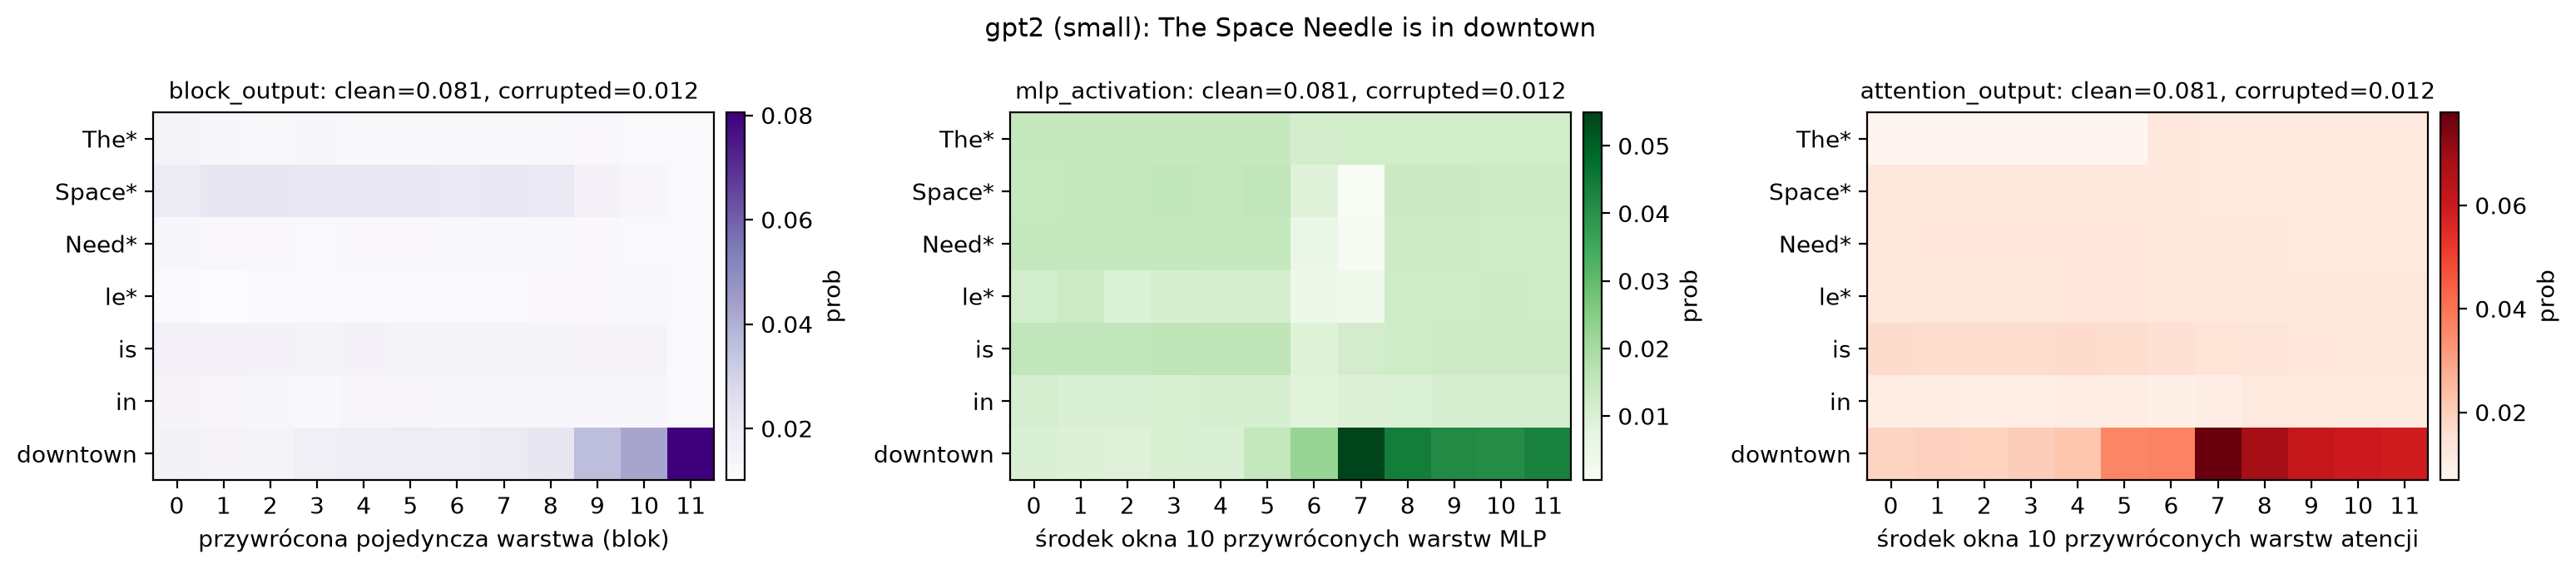

In [7]:
plot_trace_streams(small_res, suptitle="gpt2 (small): The Space Needle is in downtown");

**Wnioski (gpt2 small, szum 0,431 = 3 × std osadzeń):**

| strumień | clean | corrupted | szczyt IE | gdzie | max IE na `le` (ostatni token podmiotu) |
|---|---|---|---|---|---|
| block_output | 0,081 | 0,012 | 0,069 | `downtown`, warstwa 11 | 0,000 |
| mlp_activation | 0,081 | 0,012 | 0,043 | `downtown`, środek 7 | 0,001 |
| attention_output | 0,081 | 0,012 | 0,066 | `downtown`, środek 7 | 0,001 |

- Mały gpt2 **słabo zna fakt**: P(Seattle) = 0,081 (gpt2-xl: 0,976), a w top-5 są też Los Angeles, San Francisco, Houston. TE = 0,069, więc cały wykres to różnice rzędu setnych.
- **Brak wczesnego miejsca**: przywrócenie `le` (i każdego tokenu podmiotu) nie daje nic na żadnym strumieniu. Mały model nie buduje na ostatnim tokenie podmiotu reprezentacji, która niesie „Seattle”.
- Sygnał jest tylko na **ostatnim tokenie** w późnych warstwach (atencja i MLP ok. środka 7, blok w warstwach 9–11). Odpowiedź powstaje dopiero tam, raczej jako zgadywanie „dużego miasta w USA” z kontekstu „is in downtown” niż jako przywołanie faktu o podmiocie.
- Mechanika działa (szum obniża P, przywrócenie ostatniego tokenu w ostatniej warstwie daje dokładnie clean), ale **ciekawy obraz z ROME wymaga modelu, który naprawdę zna fakt**. Stąd gpt2-xl w kolejnych krokach.

In [8]:
del small, small_tok
import gc

gc.collect()
torch.mps.empty_cache() if device.type == "mps" else None

## 3. Plan pkt 1: Space Needle na gpt2-xl (odtworzenie notebooka #2)

Ten sam przykład co w notebooku #2 i na Rys. 1 w ROME. Model z cache HF (6,4 GB, ładowanie ok. 30 s).

Koszt: 48 warstw × 7 tokenów × 3 strumienie ≈ 1000 przebiegów gpt2-xl, czyli kilka minut na MPS. Wyniki zapisują się do `artifacts/mikolaj/space_needle__*.csv`; kolejne uruchomienie wczytuje je zamiast liczyć (Dominik też je czyta).

Szum: stała z notebooka #2 (`0,1346`), żeby wynik był porównywalny z oryginałem. Dla porównania wypisujemy 3 × std całej macierzy osadzeń.

In [ ]:
from utils.infra import load_gpt2_xl
from utils.tracing import NOTEBOOK_NOISE_LEVEL_GPT2_XL, position_summary, run_clean, run_corrupted
from utils.tracing.plot import plot_trace_grid

model, tok = load_gpt2_xl(device)
print(
    f"{model.config.n_layer} warstw, {model.config.n_embd} wymiarów, {model.num_parameters() / 1e9:.2f} mld parametrów"
)

text = "The Space Needle is in downtown"
subject = find_token_positions(tok, text, "The Space Needle")
print(tokenize(tok, text), "-> podmiot:", subject)
top_next_tokens(model, tok, text, k=5)

Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

48 warstw, 1600 wymiarów, 1.56 mld parametrów
['The', ' Space', ' Need', 'le', ' is', ' in', ' downtown'] -> podmiot: [0, 1, 2, 3]


,token,prob
0,Seattle,0.976380
1,Bellev,0.002768
2,Portland,0.002158
3,",",0.001515
4,Vancouver,0.001435


In [10]:
NOISE = NOTEBOOK_NOISE_LEVEL_GPT2_XL
seattle = next_token_prob(tok, " Seattle")
print(f"szum: notebook {NOISE:.4f}, 3*std(wte) {compute_noise_level(model):.4f}")
print("clean    ", run_clean(model, tok, text, seattle))
print("corrupted", run_corrupted(model, tok, text, subject, seattle, NOISE))

szum: notebook 0.1346, 3*std(wte) 0.1447
clean     {'prob': 0.9763795733451843}
corrupted {'prob': 0.0332452692091465}


block_output:   0%|          | 0/48 [00:00<?, ?it/s]

mlp_activation:   0%|          | 0/48 [00:00<?, ?it/s]

attention_output:   0%|          | 0/48 [00:00<?, ?it/s]

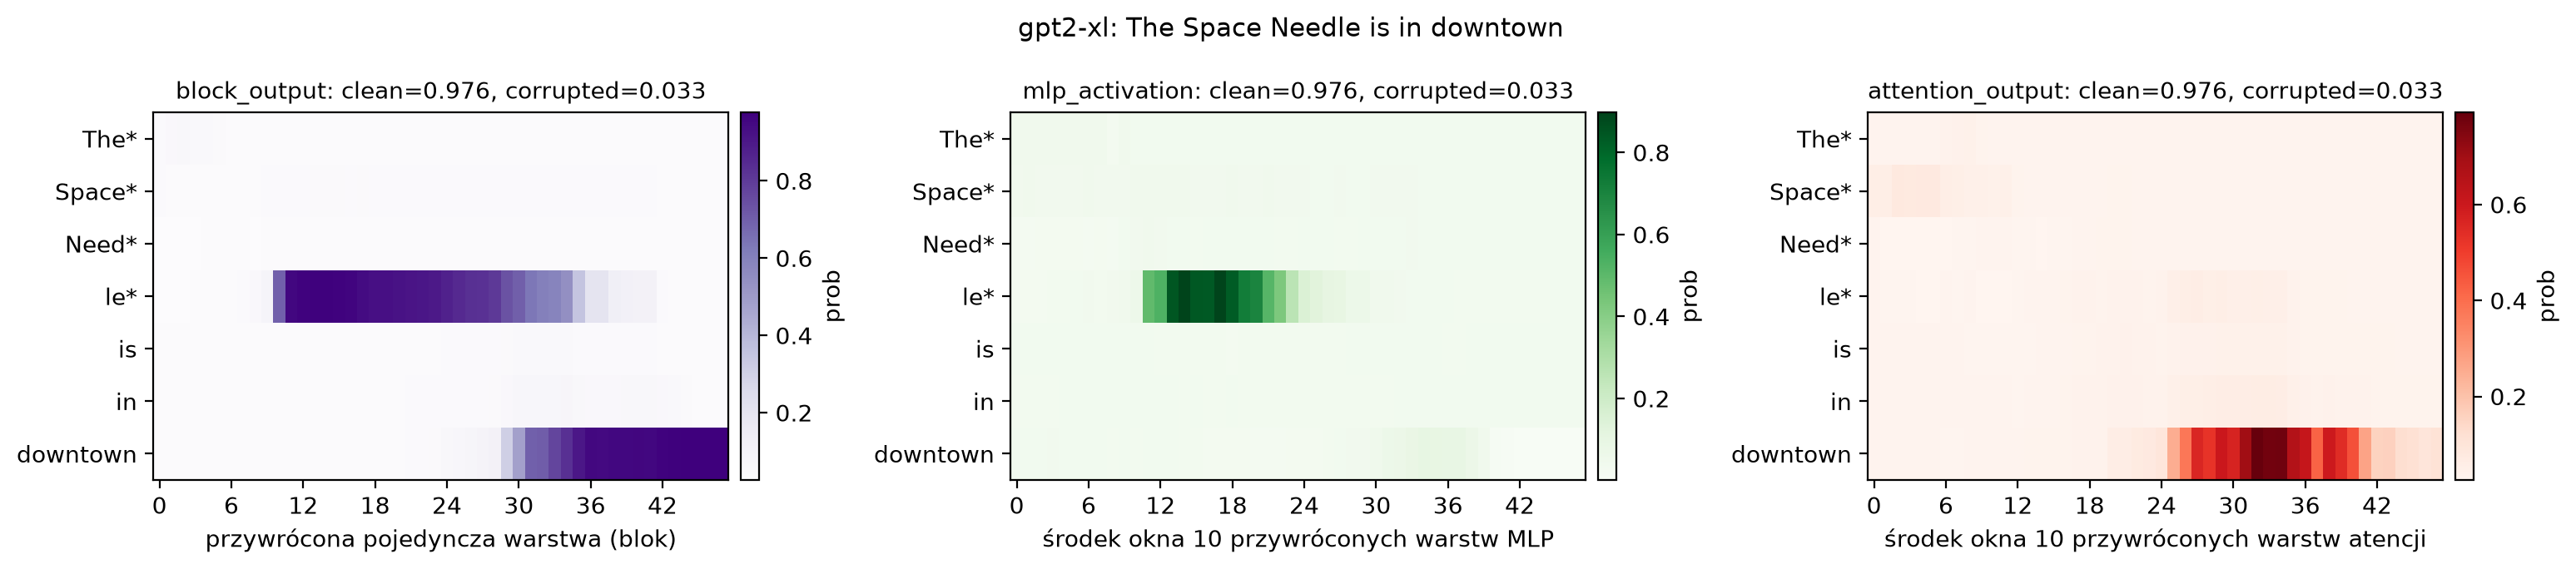

In [ ]:
space = trace_all_streams(
    model,
    tok,
    text,
    subject,
    seattle,
    out_dir=OUT,
    name="space_needle",
    noise_level=NOISE,
)
plot_trace_streams(
    space,
    suptitle="gpt2-xl: The Space Needle is in downtown",
    save_path=f"{FIGURES}/space_needle.png",
);

In [12]:
streams_summary(space)

,stream,clean,corrupted,peak_ie,peak_layer,peak_token,max_ie_last_subject,max_ie_last_token
0,block_output,0.97638,0.033245,0.943551,46,downtown,0.937074,0.943551
1,mlp_activation,0.97638,0.033245,0.864209,17,le,0.864209,0.064601
2,attention_output,0.97638,0.033245,0.758679,32,downtown,0.026434,0.758679


In [13]:
# które tokeny niosą fakt (MLP): maksymalny efekt pośredni na pozycję
position_summary(space["mlp_activation"])

,pos,token,best_layer,max_ie,noised
0,3,le,17,0.864209,True
1,6,downtown,34,0.064601,False
2,2,Need,11,0.012687,True
3,1,Space,11,0.011207,True
4,0,The,9,0.010028,True
5,4,is,28,0.001427,False
6,5,in,7,0.001389,False


**Wnioski: Space Needle na gpt2-xl (szum 0,1346; 3 × std osadzeń `wte` gpt2-xl = 0,1447, czyli prawie to samo)**

Przebieg czysty: P(Seattle) = **0,976**, zaszumiony: **0,033**, więc **TE = 0,943**. Wykres odtwarza Rys. 1 z ROME.

| strumień | szczyt IE | gdzie | max IE na `le` (ost. token podmiotu) | max IE na `downtown` (ost. token) |
|---|---|---|---|---|
| block_output | 0,944 | `downtown`, warstwa 46 | **0,937** (warstwa 14) | 0,944 |
| mlp_activation | **0,864** | **`le`, środek 17** (warstwy 12–21) | 0,864 | 0,065 |
| attention_output | **0,759** | **`downtown`, środek 32** (warstwy 27–36) | 0,026 | 0,759 |

**1. Wczesne miejsce: ostatni token podmiotu, MLP w środkowych warstwach.**
Na `le*` `block_output` daje P ≈ 0,97 już od warstwy 12 i trzyma wysoko do ok. 28. Wykres MLP pokazuje, skąd to się bierze: okna MLP ze środkiem 12–20 na `le` przywracają do 0,86 TE, a na żadnym innym tokenie MLP nic nie daje. To jest miejsce, które ROME interpretuje jako pamięć klucz → wartość: MLP w warstwach ok. 10–20 na ostatnim tokenie podmiotu „odczytuje” fakty o Space Needle.

**2. Późne miejsce: ostatni token, atencja w późnych warstwach.**
Na `downtown` `block_output` rośnie od ok. warstwy 30 (0,70 w 32, 0,95 w 36). Wykres atencji ma szczyt dokładnie tam: okna atencji ze środkiem 28–36 na `downtown` (0,76). Atencja przenosi informację z `le` na ostatni token. Atencja na `le` nic nie daje (0,026), więc na pozycji podmiotu fakt powstaje w MLP, nie w atencji.

**3. Przejście między miejscami.**
Na `le` `block_output` spada po warstwie ok. 30 (0,60 w 32, 0,20 w 36, 0,11 w 40), dokładnie wtedy, gdy na `downtown` rośnie. Po przeniesieniu późniejsze warstwy już nie czytają z `le`, więc przywracanie tam przychodzi za późno.

**4. Pozostałe tokeny podmiotu (`The*`, `Space*`, `Need*`) nie mają znaczenia** (max IE ≤ 0,05). Atencja jest przyczynowa: dopiero ostatni token podmiotu „widzi” całą nazwę.

**5. MLP na `downtown` (ok. 0,07–0,09 przy środku 32–36) jest słaby**, a ostatnie okna (środek 40+) dają nawet mniej niż corrupted (0,00–0,01). Przywracamy wtedy tylko MLP na ostatnim tokenie, a jego wejście (strumień z zaszumioną atencją) jest niespójne z przywróconym wkładem. Wniosek: na ostatnim tokenie o odpowiedzi decyduje atencja, nie MLP.

**Zgodność z ROME:** oba miejsca, ich położenie (MLP ok. 15–20 / atencja ok. 30–35 na 48 warstw) i rozdział ról MLP vs atencja zgadzają się z artykułem.

## 4. Plan pkt 2: 5 własnych faktów

**Kryteria wyboru faktu:**

1. faktograficzny, inna relacja niż Space Needle i inne między sobą (miejsce, urodzenie, język, nauka, kraj);
2. odpowiedź to **pierwszy token** po prompcie (ze spacją: `" Paris"`);
3. model **zna** fakt: odpowiedź w top-1, wysokie P w przebiegu czystym;
4. **duży TE**: odpowiedź musi zależeć od podmiotu. Jeśli P po zaszumieniu podmiotu dalej jest wysokie, model zgaduje z reszty zdania i tracing nie ma czego lokalizować.

Poniżej przegląd kandydatów (ten sam szum co w sekcji 3). Wybrane fakty mają TE ≥ 0,6. Odrzucone są pouczające:

- `Steve Jobs was the co-founder of` → ` Apple`: clean 0,82, ale **corrupted 0,79** (TE = 0,03). Model odpowiada „Apple” na samo „… was the co-founder of”, bez podmiotu. To skrót z danych treningowych, nie przywołanie faktu o Jobsie.
- `Microsoft was founded by Bill` → ` Gates`: TE = 0,17; „Bill” prawie wystarcza.
- `Toyota is a car manufacturer based in` → ` Japan`: model woli powtórzyć ` Toyota`, a TE jest ujemny.
- Colosseum, Messi, Louvre: niższe P albo konkurencyjne tokeny (` Naples`, ` soccer`/` football`, ` the`).

In [ ]:
# (nazwa, prompt, podmiot, odpowiedź)
CANDIDATES = [
    ("eiffel", "The Eiffel Tower is located in the city of", "The Eiffel Tower", " Paris"),
    ("obama", "Barack Obama was born in the state of", "Barack Obama", " Hawaii"),
    ("brazil", "The official language of Brazil is", "Brazil", " Portuguese"),
    ("einstein", "Albert Einstein developed the theory of", "Albert Einstein", " relativity"),
    ("fuji", "Mount Fuji is the tallest mountain in", "Mount Fuji", " Japan"),
    ("colosseum", "The Colosseum is located in the city of", "The Colosseum", " Rome"),
    ("jobs", "Steve Jobs was the co-founder of", "Steve Jobs", " Apple"),
    ("microsoft", "Microsoft was founded by Bill", "Microsoft", " Gates"),
    ("toyota", "Toyota is a car manufacturer based in", "Toyota", " Japan"),
]

rows = []
for name, prompt, subj, answer in CANDIDATES:
    score = next_token_prob(tok, answer)
    noised = find_token_positions(tok, prompt, subj)
    clean = run_clean(model, tok, prompt, score)["prob"]
    corrupted = run_corrupted(model, tok, prompt, noised, score, NOISE)["prob"]
    rows.append(
        {
            "fakt": name,
            "clean": clean,
            "corrupted": corrupted,
            "TE": clean - corrupted,
            "top3": list(top_next_tokens(model, tok, prompt, k=3)["token"]),
            "podmiot": [tokenize(tok, prompt)[i] for i in noised],
        }
    )
pd.DataFrame(rows).round(3)

,fakt,clean,corrupted,TE,top3,podmiot
0,eiffel,0.934,0.002,0.932,"[ Paris, E, the]","[The, E, iff, el, Tower]"
1,obama,0.976,0.014,0.963,"[ Hawaii, Illinois, Hawai]","[Bar, ack, Obama]"
2,brazil,0.943,0.155,0.788,"[ Portuguese, Spanish, English]",[ Brazil]
3,einstein,0.657,0.033,0.624,"[ relativity, general, special]","[Albert, Einstein]"
4,fuji,0.727,0.100,0.627,"[ Japan, the, North]","[Mount, Fuji]"
5,colosseum,0.568,0.001,0.567,"[ Rome, Naples, Ver]","[The, Col, os, se, um]"
6,jobs,0.821,0.791,0.030,"[ Apple, the, Pixar]","[Steve, Jobs]"
7,microsoft,0.998,0.831,0.167,"[ Gates, Hew, and]",[Microsoft]
8,toyota,0.119,0.245,-0.127,"[ Toyota, Tokyo, Japan]","[Toy, ota]"


In [15]:
SELECTED = ["eiffel", "obama", "brazil", "einstein", "fuji"]
FACTS = [c for c in CANDIDATES if c[0] in SELECTED]

Tracing 5 faktów × 3 strumienie: 6–11 tokenów, ok. 1000–1600 przebiegów na fakt, łącznie ok. 15–25 min. Wyniki są cache'owane w `artifacts/mikolaj/<fakt>__<strumień>.csv`, więc przerwane obliczenia nie przepadają w całości.

In [ ]:
facts = {}
for name, prompt, subj, answer in FACTS:
    facts[name] = trace_all_streams(
        model,
        tok,
        prompt,
        find_token_positions(tok, prompt, subj),
        next_token_prob(tok, answer),
        out_dir=OUT,
        name=name,
        noise_level=NOISE,
    )

block_output:   0%|          | 0/48 [00:00<?, ?it/s]

mlp_activation:   0%|          | 0/48 [00:00<?, ?it/s]

attention_output:   0%|          | 0/48 [00:00<?, ?it/s]

block_output:   0%|          | 0/48 [00:00<?, ?it/s]

mlp_activation:   0%|          | 0/48 [00:00<?, ?it/s]

attention_output:   0%|          | 0/48 [00:00<?, ?it/s]

... (5 outputs left out)

attention_output:   0%|          | 0/48 [00:00<?, ?it/s]

block_output:   0%|          | 0/48 [00:00<?, ?it/s]

mlp_activation:   0%|          | 0/48 [00:00<?, ?it/s]

attention_output:   0%|          | 0/48 [00:00<?, ?it/s]

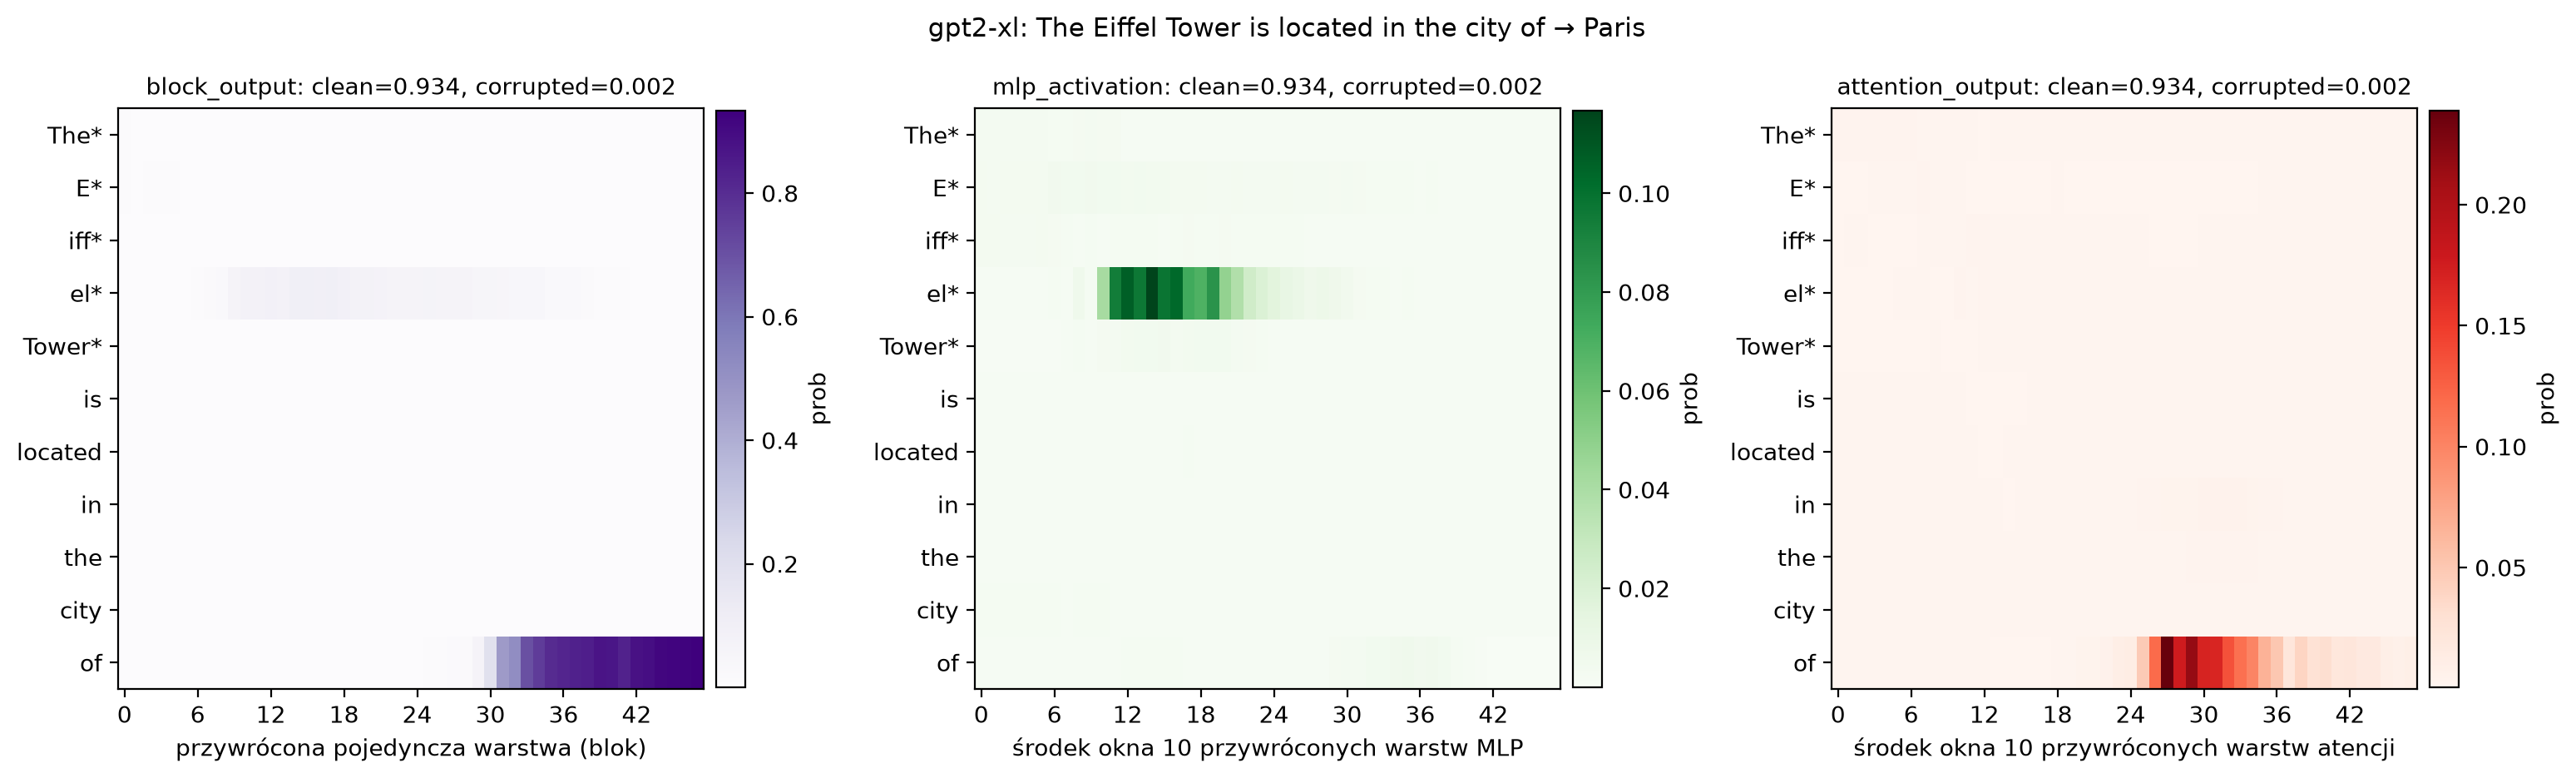

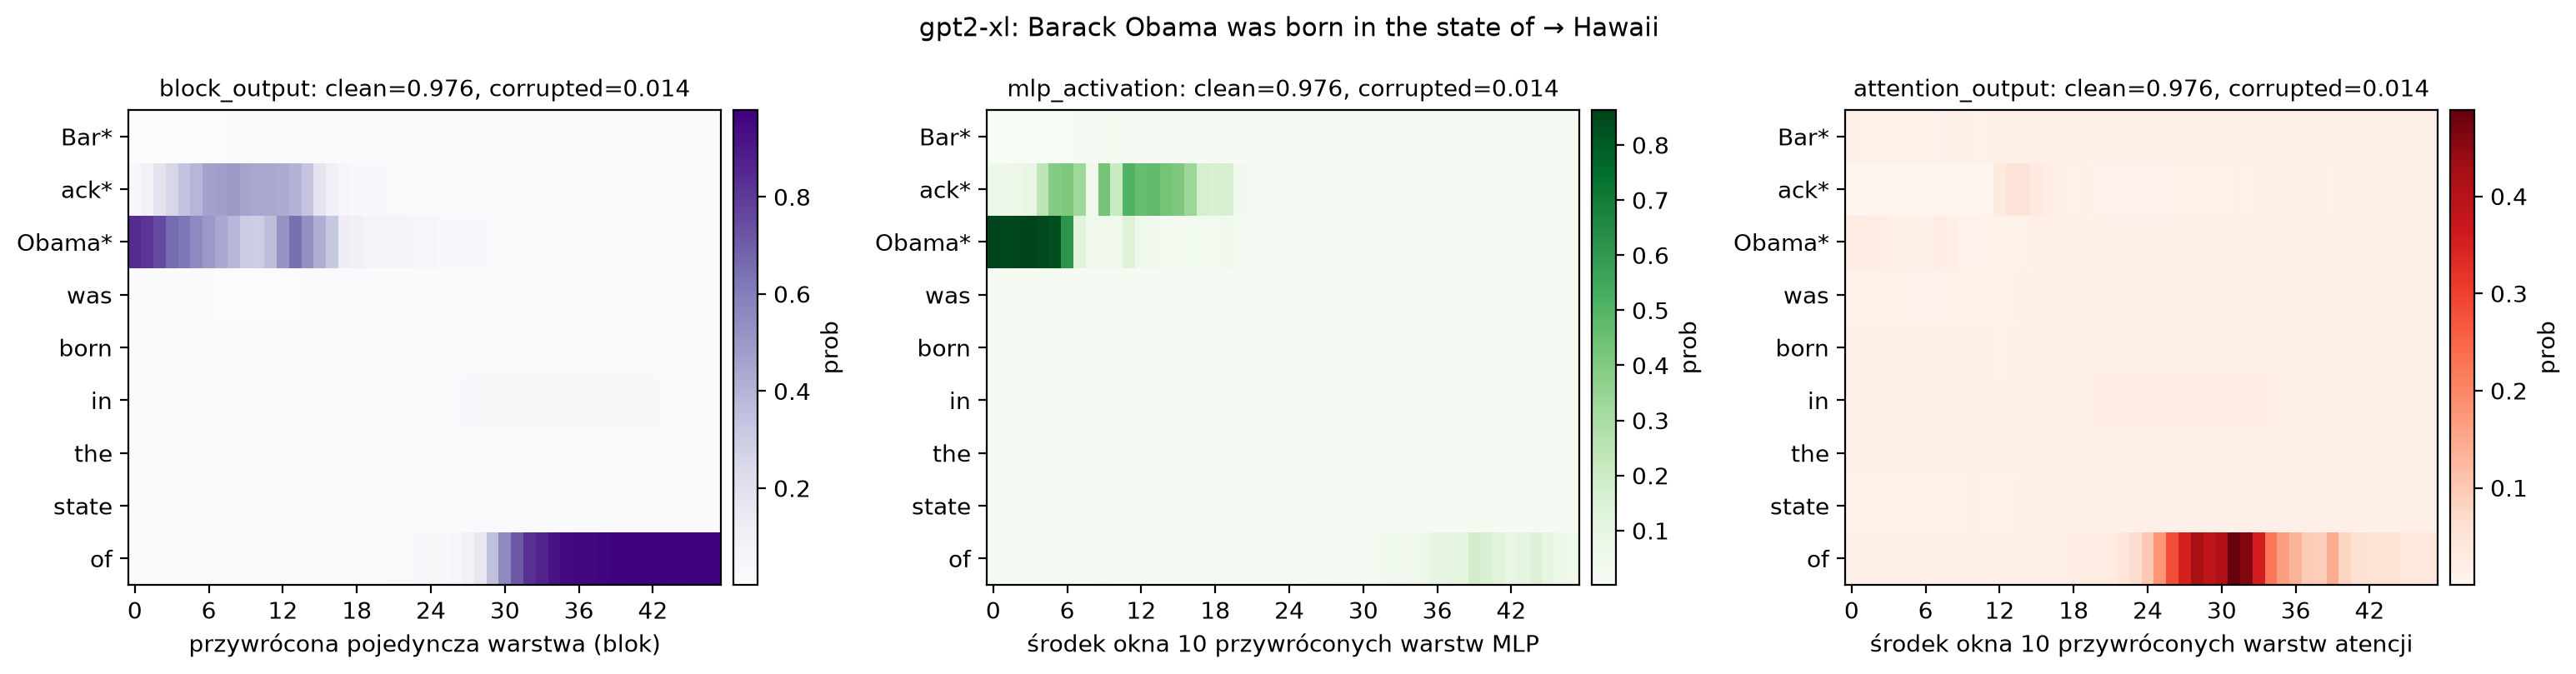

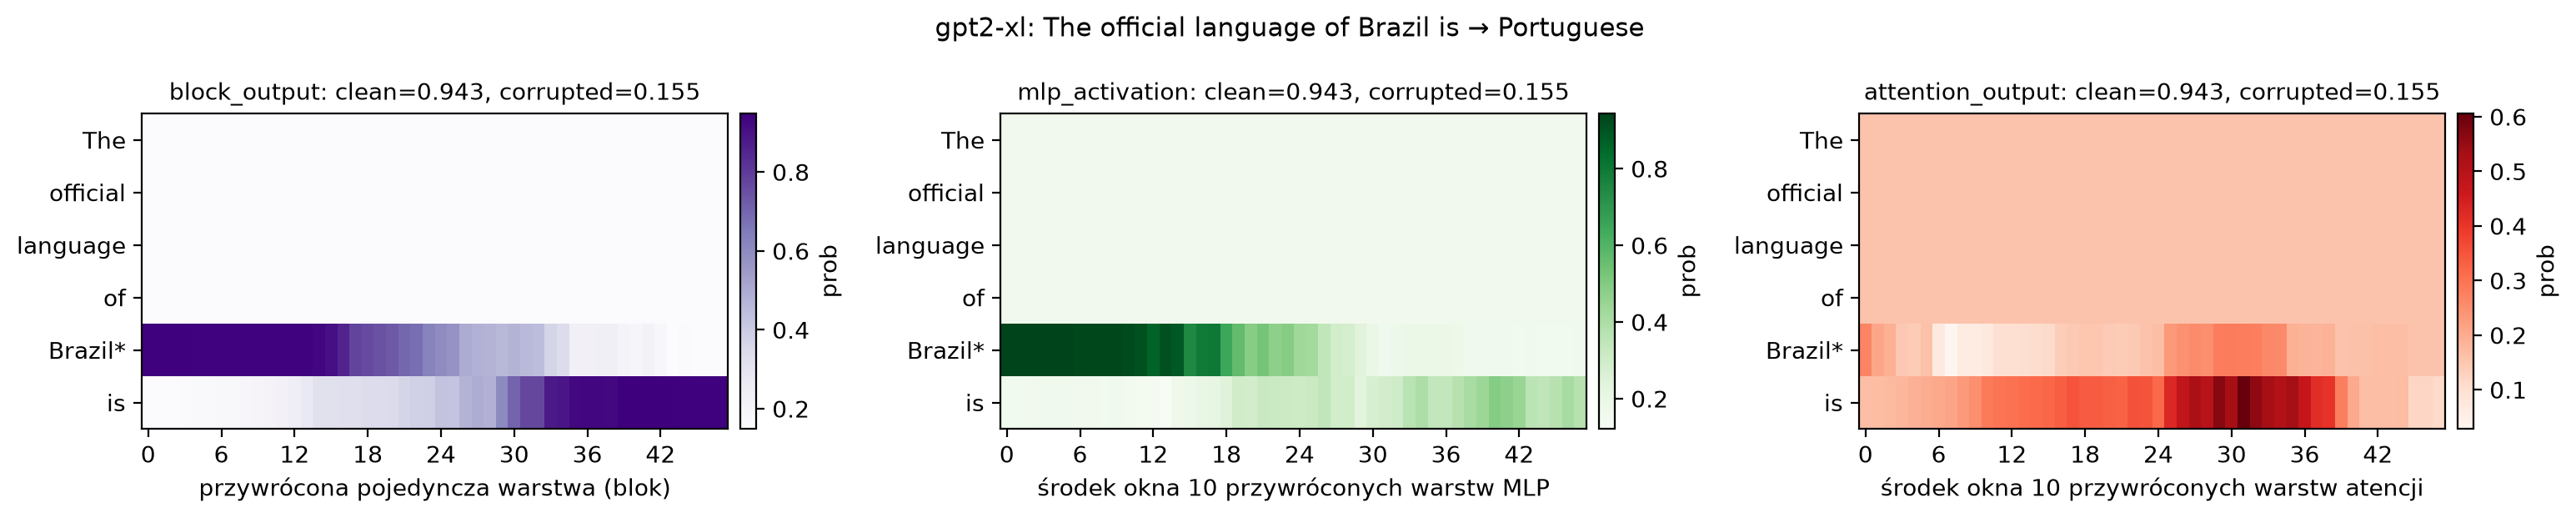

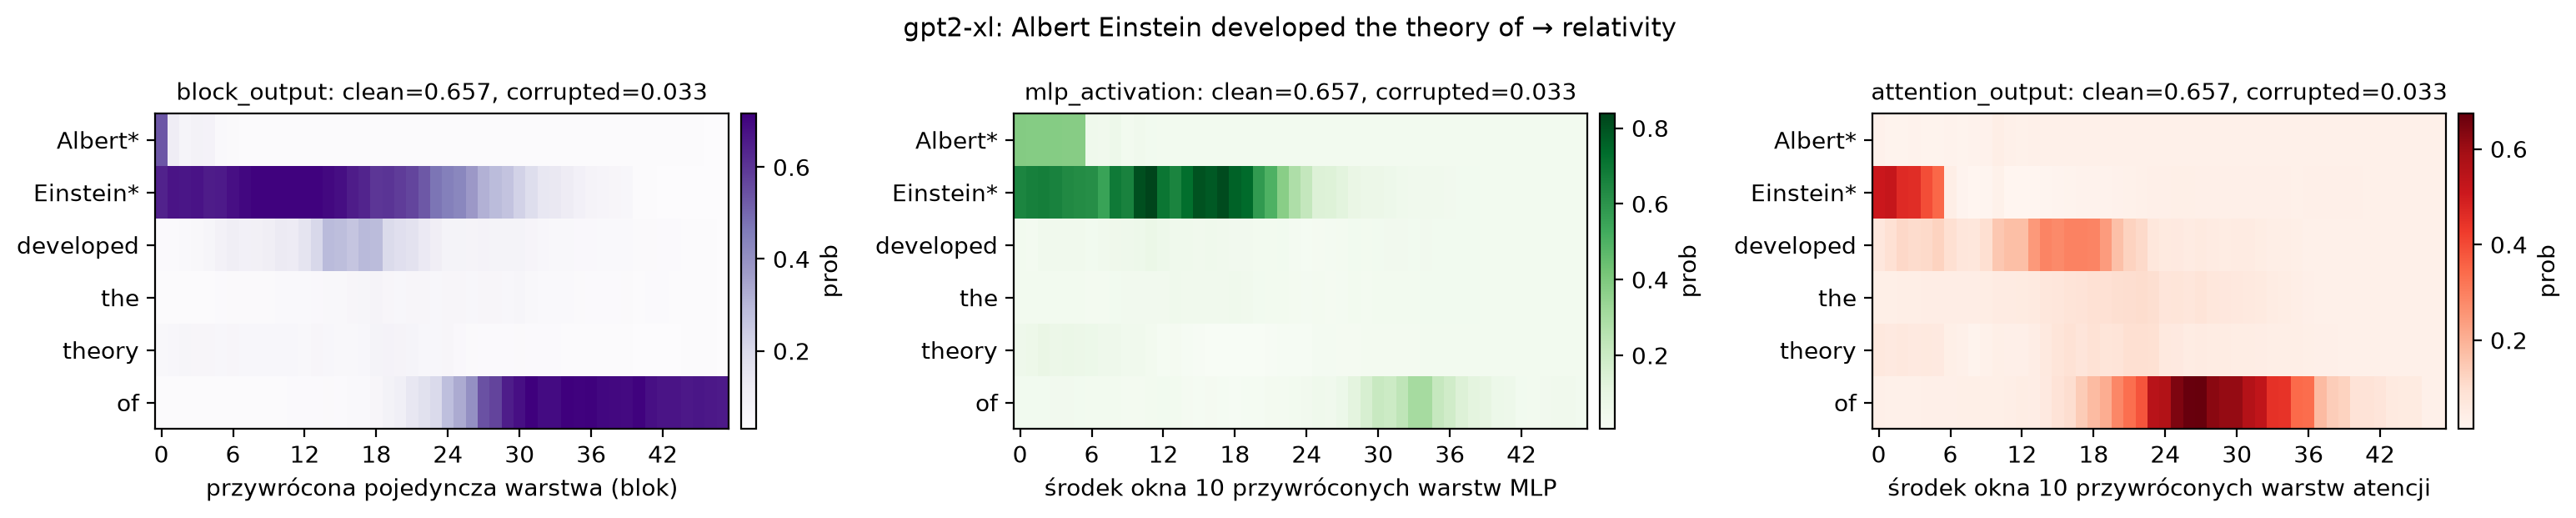

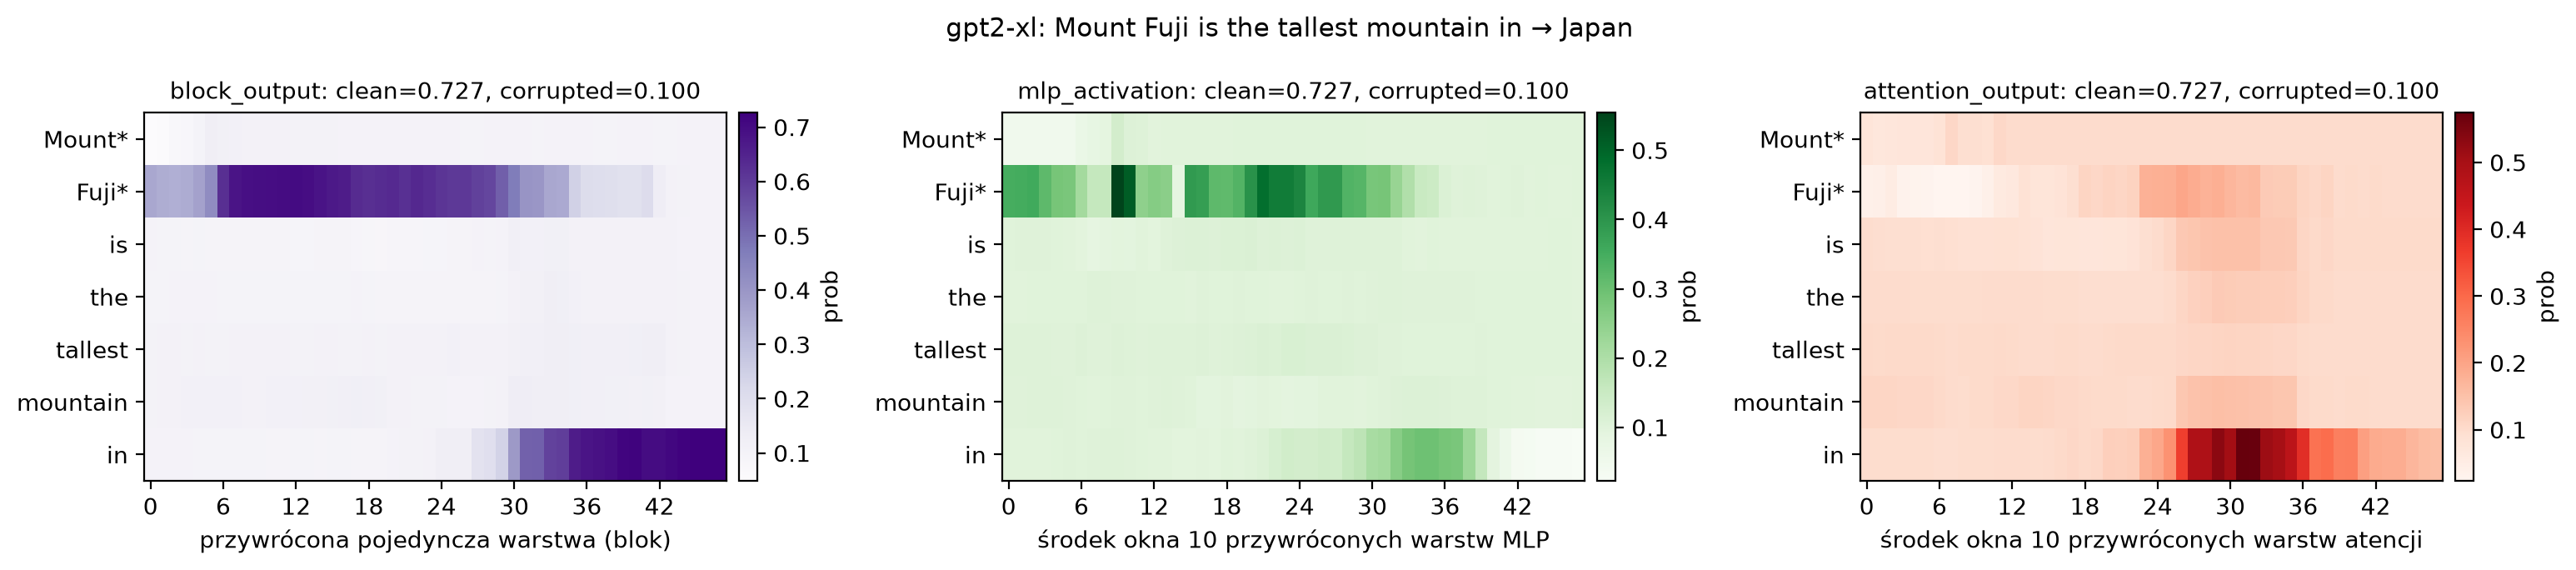

In [ ]:
for name, prompt, _, answer in FACTS:
    plot_trace_streams(
        facts[name], suptitle=f"gpt2-xl: {prompt} →{answer}", save_path=f"{FIGURES}/{name}.png"
    )

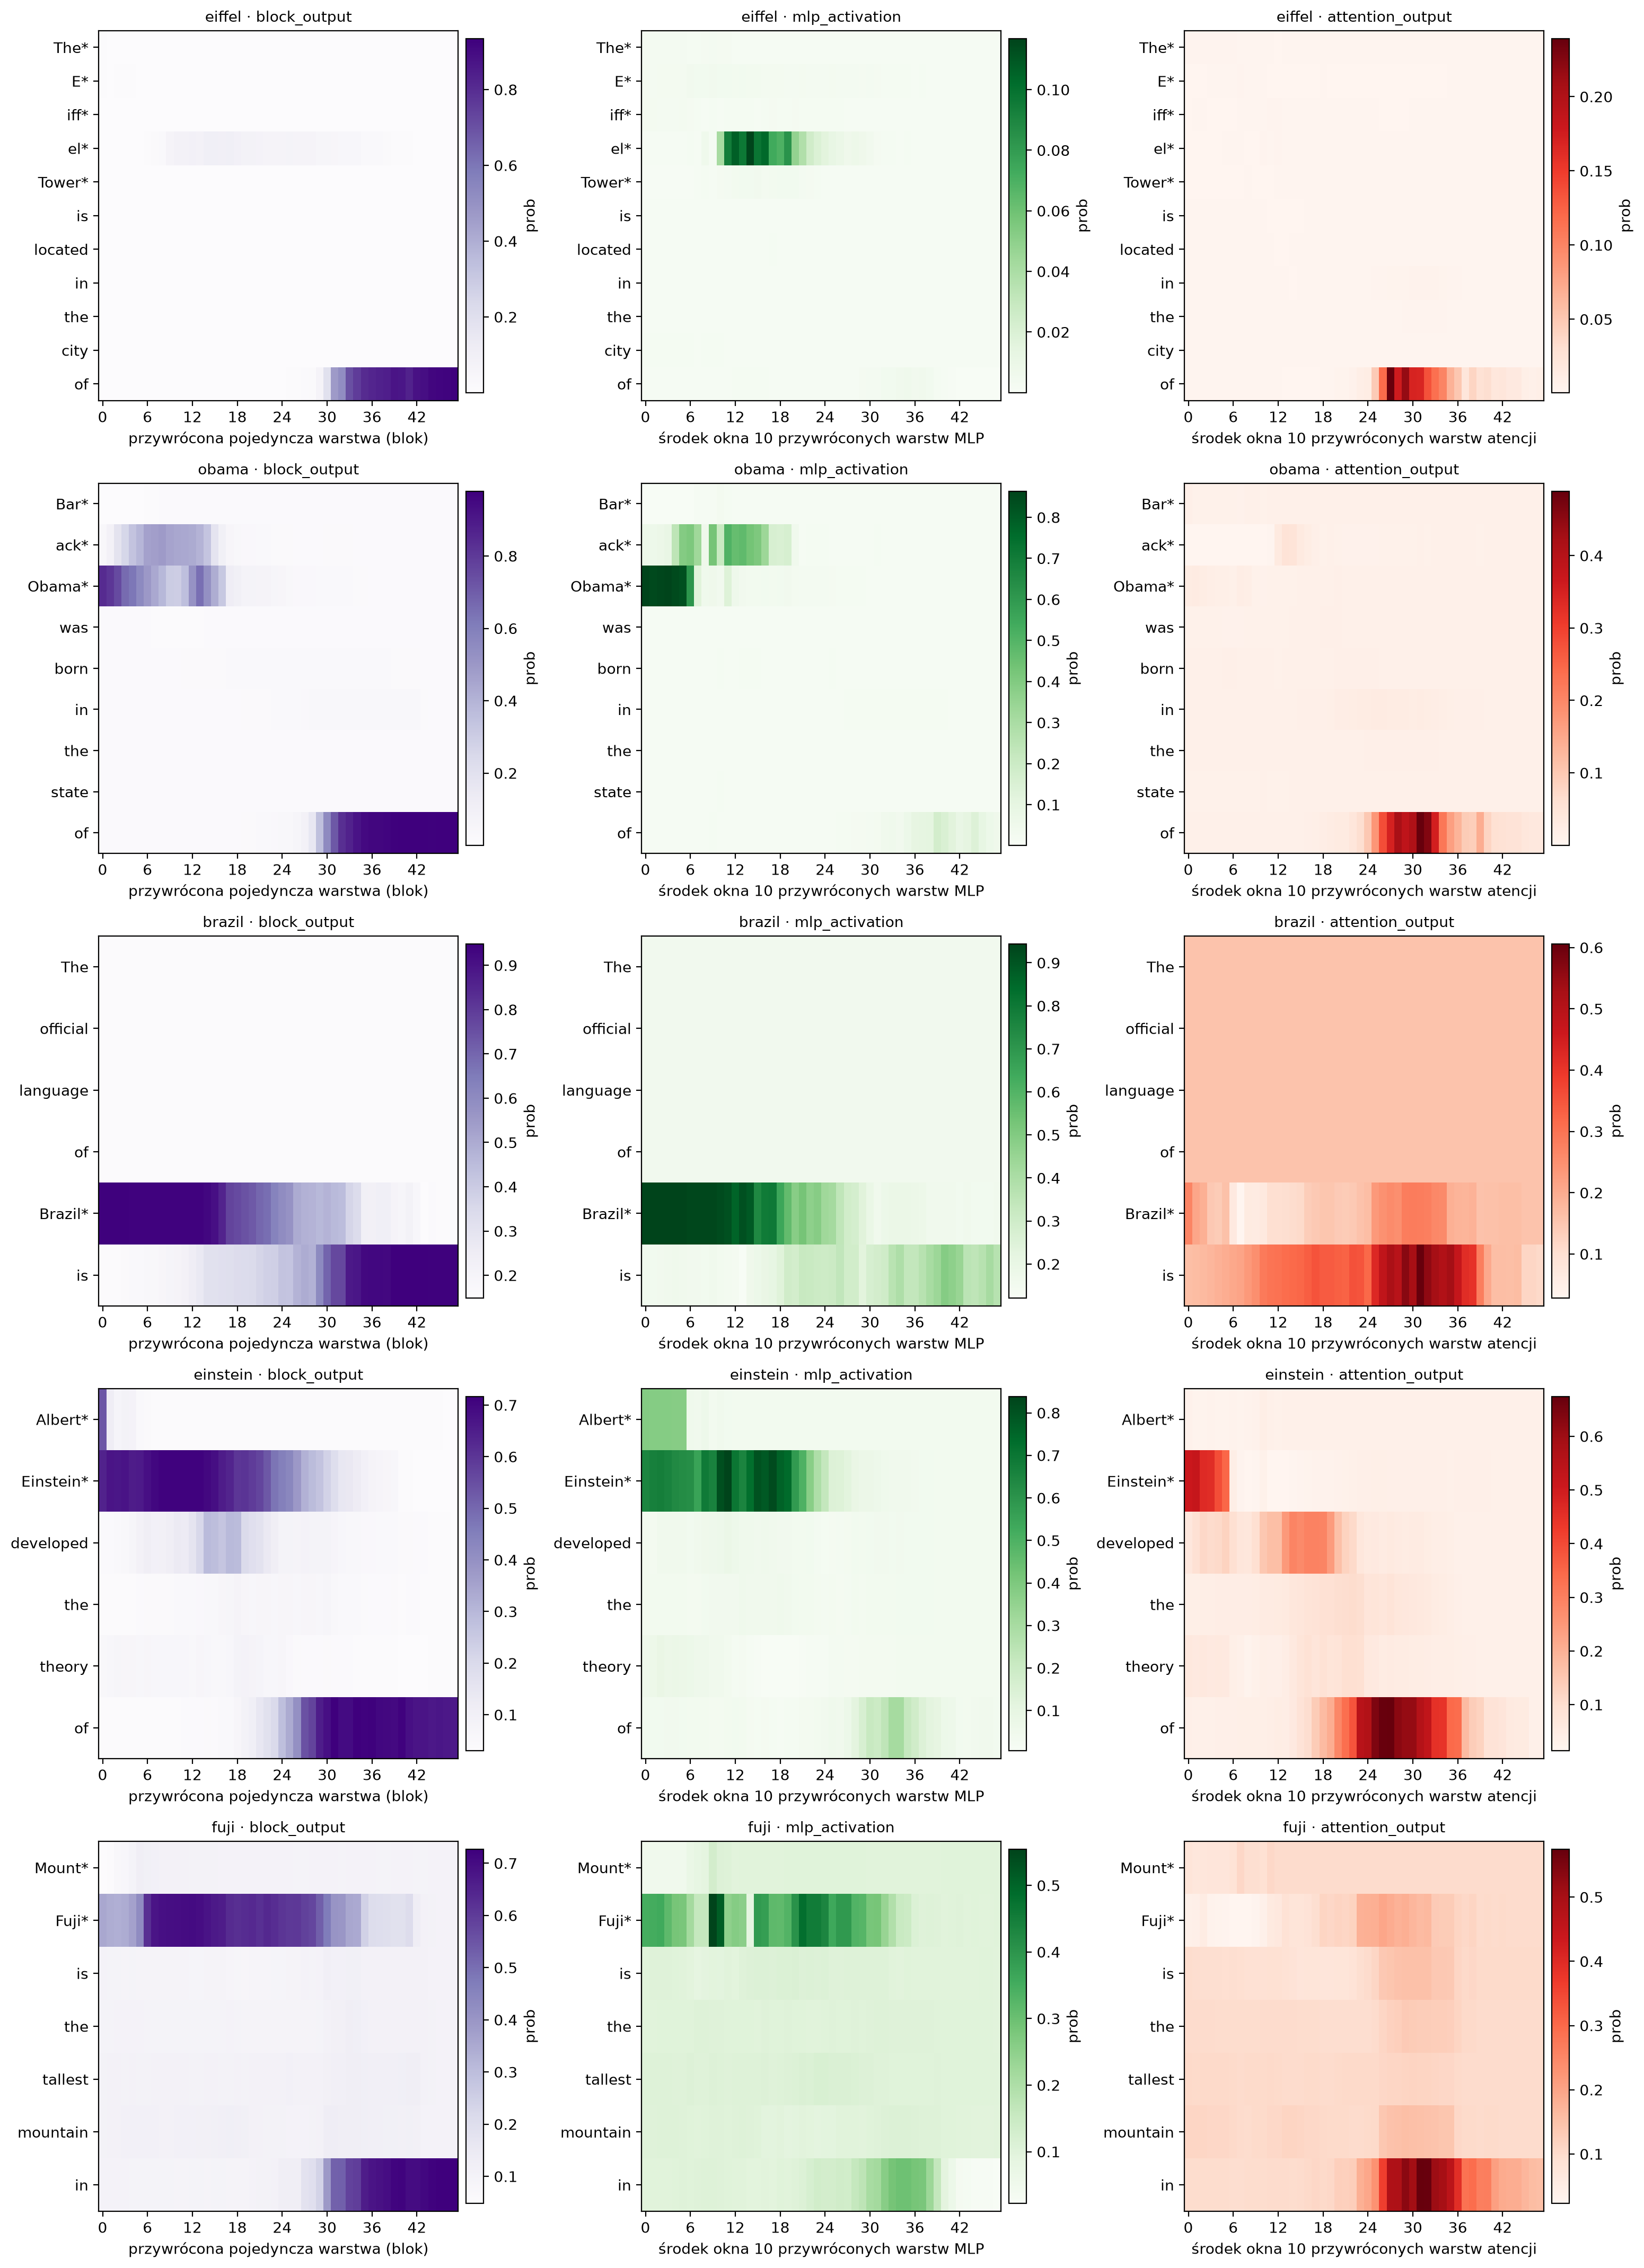

In [22]:
plot_trace_grid(facts, save_path=f"{FIGURES}/facts_grid.png");

**Wnioski: 5 własnych faktów (gpt2-xl, szum 0,1346)**

| fakt | tokeny podmiotu (*) | clean | corr. | **wczesne miejsce**: MLP na ost. tokenie podmiotu (max P, środek okna) | **późne miejsce**: atencja na ost. tokenie (max P, środek) |
|---|---|---|---|---|---|
| Space Needle → Seattle | The Space Need le | 0,976 | 0,033 | `le`: 0,90, środek 17 | `downtown`: 0,79, środek 32 |
| Barack Obama → Hawaii | Bar ack Obama | 0,976 | 0,014 | `Obama`: 0,86, środek 0 (warstwy 0–4) | `of`: 0,49, środek 31 |
| Brazil → Portuguese | Brazil | 0,943 | 0,155 | `Brazil`: 0,94, środek 4 | `is`: 0,61, środek 31 |
| Albert Einstein → relativity | Albert Einstein | 0,657 | 0,033 | `Einstein`: 0,84, środek 11 | `of`: 0,67, środek 27 |
| Mount Fuji → Japan | Mount Fuji | 0,727 | 0,100 | `Fuji`: 0,56, środek 9 | `in`: 0,58, środek 31 |
| Eiffel Tower → Paris | The E iff el Tower | 0,934 | 0,002 | **brak** (`Tower`: 0,005; `el`: 0,12) | `of`: 0,24, środek 27 |

(Wartości to P(odpowiedź) po przywróceniu; IE = P − corrupted.)

**1. Późne miejsce jest uniwersalne.** We wszystkich faktach atencja na **ostatnim tokenie** ma szczyt przy środku okna **27–32**, a `block_output` na ostatnim tokenie rośnie od ok. warstwy 28–32 do wartości clean. Przeniesienie faktu na pozycję predykcji odbywa się w tym samym zakresie warstw niezależnie od relacji.

**2. Wczesne miejsce jest na ostatnim tokenie podmiotu i w MLP, ale jego warstwa zależy od podmiotu.**
- `Obama`, `Brazil`: MLP w **pierwszych warstwach** (okno 0–4 / 0–9). To częste, jednotokenowe nazwy: już osadzenie tokenu niemal jednoznacznie wskazuje encję, a pierwsze MLP wystarczą, żeby dopisać fakt.
- `Fuji` (środek 9), `Einstein` (11), `le` w Space Needle (17): podmioty złożone z kilku tokenów albo rzadsze nazwy. Model musi najpierw **złożyć nazwę** z kilku tokenów, więc fakt pojawia się w głębszych warstwach. Przy Einsteinie widać ten etap wprost: atencja na `Einstein` w warstwie ok. 1 daje 0,52, czyli wczesna atencja dokleja „Albert” do „Einstein”.
- Ostatni token podmiotu znów okazuje się kluczowy. Wcześniejsze tokeny podmiotu dają mało (wyjątek: `ack` w „Barack” 0,49 w MLP, bo „Barack” samo w sobie mocno wskazuje Obamę).

**3. Uwaga przy podmiotach jednotokenowych.** Dla `Brazil` przywrócenie `block_output` w warstwie 0 na jedynym zaszumionym tokenie daje 0,94 = clean. To efekt trywialny: zaszumiony jest tylko ten token, a jego stan po warstwie 0 zależy wyłącznie od niego i czystych tokenów przed nim, więc przywrócenie **cofa całe zaszumienie**. Informatywne jest dopiero to, **do której warstwy** `Brazil` wystarcza: P spada po ok. warstwie 20–28, gdy fakt przechodzi na `is`.

**4. Eiffel Tower: brak wczesnego miejsca na pojedynczym tokenie.** Model zna fakt (0,934) i podmiot jest kluczowy (TE = 0,932), ale przywrócenie dowolnego **jednego** tokenu podmiotu nic nie daje (max 0,12 na `el`), a atencja na ostatnim tokenie odzyskuje tylko 0,24. Hipotezy:
- podmiot ma **5 zaszumionych tokenów**; informacja o „Eiffel” jest na `el`, a `Tower` to słowo ogólne, więc żaden pojedynczy token nie niesie całości, a późna atencja czyta z kilku zaszumionych pozycji naraz;
- szum (corrupted 0,002) niszczy kontekst mocniej niż w innych faktach.
Do sprawdzenia w sekcji 5: przywrócenie wszystkich tokenów podmiotu naraz.

**5. Brazil: wysokie corrupted (0,155).** „The official language of … is” zawęża odpowiedź do nazw języków bez znajomości kraju (top-3: Portuguese, Spanish, English), dlatego TE jest mniejszy i późne miejsce startuje wyżej (0,15 → 0,94 na `is`).

## 5. Analiza i pytania pomocnicze

### 5.1 Zestawienie wszystkich faktów

Wyniki wczytywane z `artifacts/mikolaj/` (bez liczenia). `max_ie_last_subject` = najlepszy efekt na ostatnim tokenie podmiotu (wczesne miejsce), `max_ie_last_token` = na ostatnim tokenie (późne miejsce).

In [ ]:
from utils.tracing import load_trace_streams

ALL = {"space_needle": load_trace_streams(OUT, "space_needle")} | {
    name: load_trace_streams(OUT, name) for name in SELECTED
}
pd.concat(
    {name: streams_summary(res) for name, res in ALL.items()}, names=["fakt", None]
).droplevel(1).round(3)

,stream,clean,corrupted,peak_ie,peak_layer,peak_token,max_ie_last_subject,max_ie_last_token
fakt,,,,,,,,
space_needle,block_output,0.976,0.033,0.944,46,downtown,0.937,0.944
space_needle,mlp_activation,0.976,0.033,0.864,17,le,0.864,0.065
space_needle,attention_output,0.976,0.033,0.759,32,downtown,0.026,0.759
eiffel,block_output,0.934,0.002,0.932,47,of,0.002,0.932
eiffel,mlp_activation,0.934,0.002,0.115,14,el,0.003,0.004
eiffel,attention_output,0.934,0.002,0.237,27,of,0.001,0.237
obama,block_output,0.976,0.014,0.965,45,of,0.830,0.965
obama,mlp_activation,0.976,0.014,0.849,0,Obama,0.849,0.161
obama,attention_output,0.976,0.014,0.475,31,of,0.014,0.475


### 5.2 Eiffel Tower: przywracanie grupy tokenów naraz

W sekcji 4 przy Eiffel Tower żaden **pojedynczy** token podmiotu nie przywracał faktu. Hipoteza: informacja jest rozłożona na kilka tokenów (`E iff el` niesie „Eiffel”, `Tower` mówi, że to wieża), a przywrócenie jednego zostawia resztę zaszumioną.

Test: `trace_groups` (moduł `utils/tracing/groups.py`) w każdej warstwie przywraca **zbiór pozycji jednocześnie**. Porównujemy grupy: cały podmiot, `E iff el`, `el + Tower`, sam `Tower`. Kontrola: Space Needle, cały podmiot vs sam `le`. Koszt: ok. 5 min (wyniki cache'owane).

In [ ]:
from utils.tracing import groups_summary, trace_groups
from utils.tracing.plot import plot_groups

eiffel_prompt = "The Eiffel Tower is located in the city of"
eiffel_subject = find_token_positions(tok, eiffel_prompt, "The Eiffel Tower")  # [0, 1, 2, 3, 4]
eiffel_groups = trace_groups(
    model,
    tok,
    eiffel_prompt,
    eiffel_subject,
    next_token_prob(tok, " Paris"),
    groups={
        "cały podmiot": eiffel_subject,
        "E iff el": [1, 2, 3],
        "el + Tower": [3, 4],
        "Tower": [4],
    },
    noise_level=NOISE,
    out_path=OUT / "eiffel__groups",
)
space_groups = trace_groups(
    model,
    tok,
    text,
    subject,
    seattle,
    groups={"cały podmiot": subject, "le": [3]},
    noise_level=NOISE,
    out_path=OUT / "space_needle__groups",
)
groups_summary(eiffel_groups).round(3)

max_prob                                   best_layer  \
stream       attention_output block_output mlp_activation attention_output   
group                                                                        
E iff el                0.003        0.309          0.305             10.0   
Tower                   0.002        0.004          0.005             17.0   
cały podmiot            0.003        0.925          0.913             13.0   
el + Tower              0.003        0.409          0.507             28.0   

                                          
stream       block_output mlp_activation  
group                                     
E iff el              3.0           10.0  
Tower                22.0           15.0  
cały podmiot          8.0            4.0  
el + Tower           13.0           12.0

In [20]:
groups_summary(space_groups).round(3)

max_prob                                   best_layer  \
stream       attention_output block_output mlp_activation attention_output   
group                                                                        
cały podmiot             0.09        0.983          0.982              2.0   
le                       0.06        0.970          0.897             27.0   

                                          
stream       block_output mlp_activation  
group                                     
cały podmiot          4.0            2.0  
le                   14.0           17.0

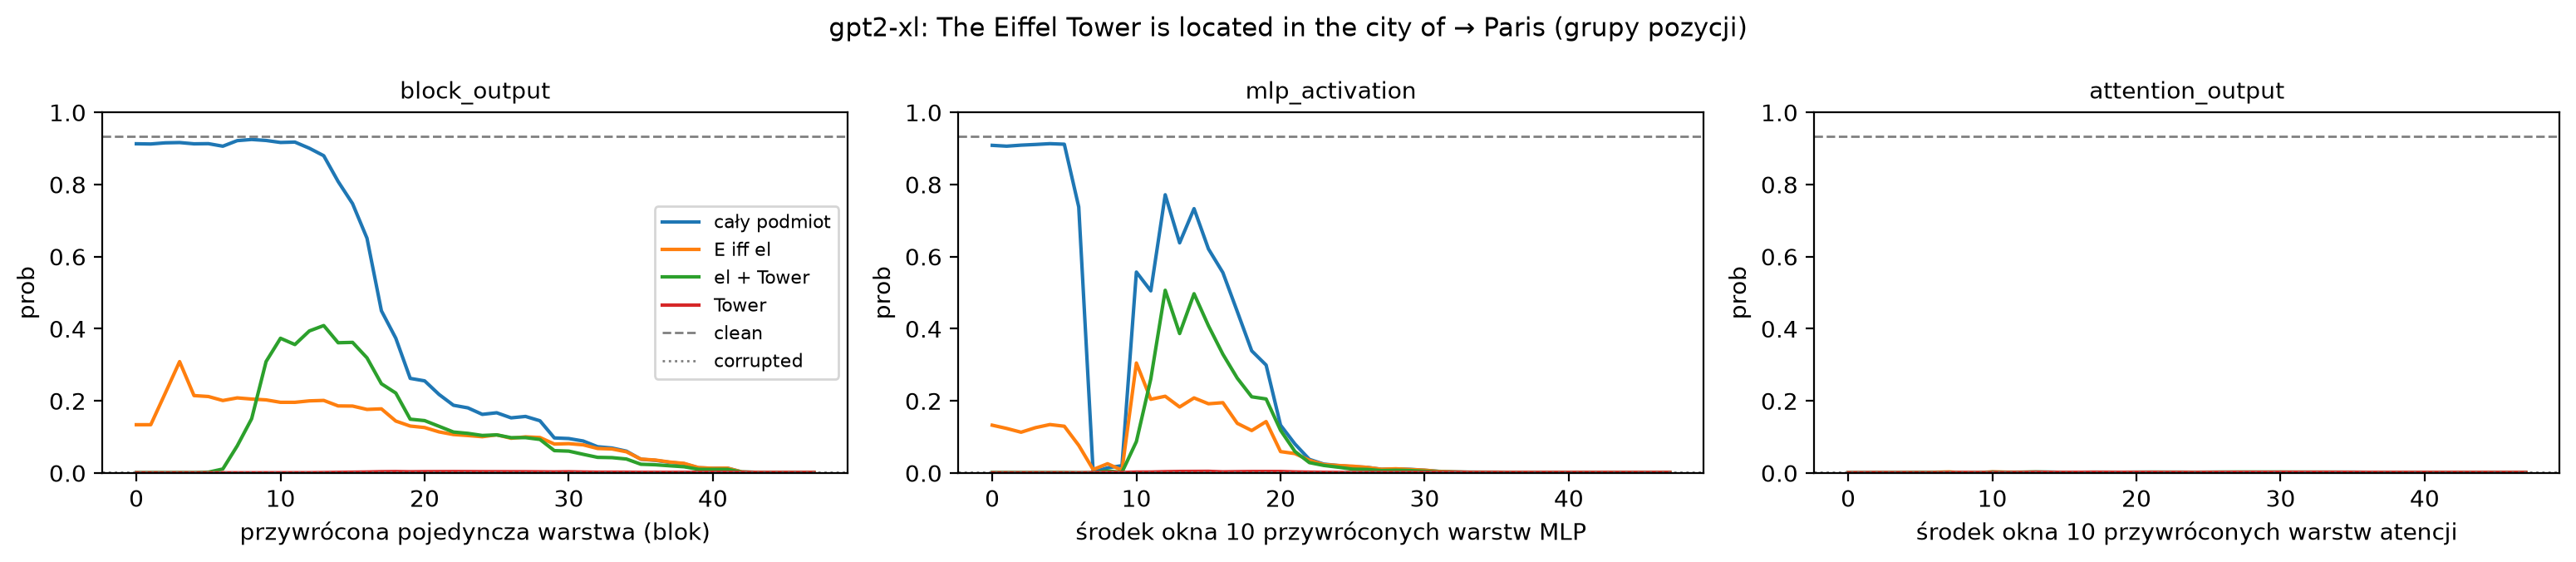

In [ ]:
plot_groups(
    eiffel_groups,
    title="gpt2-xl: The Eiffel Tower is located in the city of → Paris (grupy pozycji)",
    save_path=f"{FIGURES}/eiffel_groups.png",
);

**Wnioski: przywracanie grup tokenów**

| grupa (Eiffel) | `block_output` max (warstwa) | `mlp_activation` max (środek) | `attention_output` max |
|---|---|---|---|
| cały podmiot `The E iff el Tower` | **0,925** (8) | **0,913** (4) | 0,003 |
| `el + Tower` | 0,409 (13) | 0,507 (12) | 0,003 |
| `E iff el` | 0,309 (3) | 0,305 (10) | 0,003 |
| `Tower` (ost. token podmiotu) | 0,004 | 0,005 | 0,002 |

Kontrola, Space Needle: cały podmiot 0,983 (blok) / 0,982 (MLP), sam `le` 0,970 / 0,897.

1. **Hipoteza się potwierdza: przy Eiffel Tower informacja jest rozłożona na kilka tokenów podmiotu.** Przywrócenie całego podmiotu odzyskuje fakt (0,925 przy clean 0,934). Żaden pojedynczy token tego nie robi, a `Tower` sam w sobie nic nie daje. `el + Tower` daje 0,4–0,5: potrzebne jest zarówno „Eiffel” (`el`), jak i „Tower”, i to razem. Dla porównania przy Space Needle ostatni token `le` niesie prawie wszystko (0,970 vs 0,983 dla całego podmiotu).
2. **Wczesne miejsce dalej jest w MLP na podmiocie.** Okna MLP na grupach `el + Tower` i `E iff el` mają szczyt przy środku 10–14, czyli w tych samych warstwach co MLP przy Space Needle. Mechanizm jest ten sam, tylko rozłożony na więcej niż jedną pozycję.
3. **Atencja na pozycjach podmiotu nic nie daje (≤ 0,003)**, tak jak we wszystkich faktach: przywrócenie samej atencji na podmiocie nie odbudowuje faktu.
4. **Fakt opuszcza podmiot wcześniej niż przy Space Needle.** Przywrócenie całego podmiotu działa do ok. warstwy 13, a w warstwie 20 daje już tylko 0,26. Przy Space Needle `le` wystarczał do ok. warstwy 28. Pojedyncza pozycja `of` przejmuje fakt dopiero od ok. warstwy 30 (0,52 w 32). W warstwach ok. 16–30 informacja jest więc na **kilku pozycjach naraz** między podmiotem a ostatnim tokenem („is located in the city”), a żadna z nich osobno nie wystarcza. Długi prompt (6 tokenów między podmiotem a odpowiedzią) rozprasza przepływ.
5. **Anomalia w MLP dla całego podmiotu:** przy środkach okna 7–9 (warstwy 2–13) wynik spada prawie do zera, choć okna wcześniejsze i późniejsze dają ok. 0,9 / 0,7. Przywracamy wtedy MLP na wszystkich pięciu tokenach podmiotu, ale zostawiamy zaszumione wejście do nich i atencję. Prawdopodobnie powstaje stan niespójny, który model odczytuje gorzej niż sam szum. Nie badałem tego dalej.

**Wniosek ogólny:** standardowy causal tracing (jedna pozycja naraz) zakłada, że jest token, który sam niesie informację. To prawda dla większości faktów (Space Needle, Obama, Brazil, Einstein, Fuji), ale nie zawsze. Przywracanie grup pozycji pozwala znaleźć przypadki, w których informacja jest rozproszona.

### 5.3 Pytania pomocnicze

**Na czym polega technika Causal Tracing?**

Causal Tracing to zastosowanie analizy mediacji do sieci neuronowej: szukamy, przez które stany ukryte przepływa wpływ wejścia (podmiotu) na wyjście (prawdopodobieństwo poprawnej odpowiedzi). Wykonujemy trzy przebiegi:

1. **czysty**: zapisujemy wszystkie stany ukryte i $P(o)$;
2. **zaszumiony**: do osadzeń tokenów podmiotu dodajemy szum gaussowski $\mathcal{N}(0, (3\sigma)^2)$, model traci informację o podmiocie i $P_*(o)$ spada; różnica $\text{TE} = P(o) - P_*(o)$ to efekt całkowity podmiotu;
3. **zaszumiony z przywróceniem**: jak w 2, ale w jednym miejscu (warstwa $l$, pozycja $i$, komponent) wstawiamy stan z przebiegu czystego. $\text{IE} = P_{*,\,\text{clean } h_i^{(l)}}(o) - P_*(o)$ mówi, ile efektu odzyskuje ten jeden stan.

Mapa IE dla wszystkich warstw × pozycji pokazuje, gdzie model przechowuje i przenosi fakt. Dla bloku przywracamy jedną warstwę, dla MLP i atencji okno 10 warstw, bo wkład pojedynczego podmodułu jest mały i rozłożony. W ROME wyniki tracingu wskazały MLP w środkowych warstwach na ostatnim tokenie podmiotu jako miejsce, które warto edytować.

**Które tokeny podmiotu mają największy wpływ na predykcję?**

**Ostatni token podmiotu**: `le` w „Space Needle” (IE 0,94 z TE 0,94), `Obama`, `Einstein`, `Fuji`, `Brazil` (jedyny token). Wcześniejsze tokeny podmiotu (`The`, `Space`, `Need`, `Albert`, `Mount`) dają IE bliskie 0. Powód: atencja jest przyczynowa, więc dopiero ostatni token podmiotu „widzi” całą nazwę i dopiero na nim model może zbudować reprezentację encji i dopisać do niej fakty (MLP). Wyjątek to „Barack” (`ack`: 0,49 w MLP), bo już „Barack” prawie jednoznacznie wskazuje osobę. Drugi wyjątek to Eiffel Tower: żaden pojedynczy token nie wystarcza, potrzebny jest cały podmiot (sekcja 5.2).

**Dlaczego wzorce aktywacji dla `attention_output`, `block_output` i `mlp_activation` różnią się?**

Bo mierzą różne rzeczy w strumieniu rezydualnym:

- **`block_output`** to **cały stan** tokenu po warstwie $l$, czyli suma wszystkiego, co policzono wcześniej. Jego przywrócenie odbudowuje wszystko, co model wie w tym miejscu, dlatego widać na nim **oba** miejsca: podmiot w środkowych warstwach i ostatni token w późnych. Jasny obszar na ostatnim tokenie w ostatnich warstwach jest trywialny: ten stan wprost wyznacza predykcję.
- **`mlp_activation`** to **wkład MLP**. MLP działa na jednym tokenie, bez patrzenia na inne, i według ROME pełni rolę pamięci klucz → wartość. Dlatego jest jasny **na ostatnim tokenie podmiotu w środkowych warstwach** (Space Needle: środek 17, Einstein 11, Fuji 9, Obama i Brazil 0–4): tam MLP dopisuje fakty o podmiocie. Na ostatnim tokenie MLP prawie nic nie daje.
- **`attention_output`** to **wkład atencji**, jedynego mechanizmu przenoszącego informację **między pozycjami**. Dlatego jest jasny **na ostatnim tokenie w późnych warstwach** (środek 27–32 we wszystkich faktach): tam atencja kopiuje fakt z podmiotu na pozycję, z której model przewiduje odpowiedź. Na podmiocie atencja jest ważna tylko przy składaniu wielotokenowej nazwy (Einstein: atencja na `Einstein` w warstwie ok. 1).

Razem dają obraz przepływu: **MLP na podmiocie wydobywa fakt, atencja przenosi go na koniec zdania, a `block_output` pokazuje sumę obu etapów.**

## 6. Survey *Knowledge Editing for Large Language Models* (I.1)

Wang, Zhu, Liu, Zheng, Chen, Li, *Knowledge Editing for Large Language Models: A Survey*, 2024 ([arXiv 2310.16218](https://arxiv.org/abs/2310.16218)). Notatka oparta na wersji HTML (v4), rozdz. 3–5.

### Po co edycja wiedzy

LLM-y uczą się faktów w czasie pretreningu, a fakty się starzeją albo są błędne. Pełny ponowny trening jest za drogi. Zwykłe dostrajanie (*fine-tuning*) na nowych danych grozi nadmiernym dopasowaniem i utratą innej wiedzy. RAG zależy od jakości wyszukiwania. **Knowledge-based Model Editing (KME)** ma zmienić **konkretną** wiedzę w modelu, nie psując reszty.

### Definicja zadania (rozdz. 3)

- Wiedza to **krotka** $t = (s, r, o)$: podmiot, relacja, obiekt, np. *(Space Needle, located in, Seattle)*.
- **Edycja** to para $e = (t, t^*) = (s, r, o \rightarrow o^*)$, np. *Seattle → Tokyo*.
- $(s, r)$ zamienia się na prompt $x$ w języku naturalnym („The Space Needle is in downtown”), a wyjście $y$ na obiekt. Ta sama krotka ma wiele promptów (parafrazy).
- **Zakres edycji:**
  - $\mathcal{X}_e = I(s, r)$: wejścia **w zakresie** (wszystkie sformułowania pytania o ten fakt),
  - $\mathcal{Y}_e = O(s, r, o)$: stare odpowiedzi, $\mathcal{Y}_e^* = O^*(s, r, o^*)$: nowe odpowiedzi,
  - dla zbioru edycji $\mathcal{E}$: $\mathcal{X}_\mathcal{E} = \bigcup_{e \in \mathcal{E}} \mathcal{X}_e$,
  - wejścia **poza zakresem**: $\mathcal{X} \setminus \mathcal{X}_\mathcal{E}$ (w praktyce wybrany podzbiór $\mathcal{O}_e$).
- Model $f$ o parametrach $\phi$; metoda edycji $M$ daje model $f^* = M(f; \mathcal{E})$ o parametrach $\phi^*$.

**Cel:**

$$\min\ \mathbb{E}_{e \in \mathcal{E}}\ \mathbb{E}_{x, y^* \in \mathcal{X}_e, \mathcal{Y}_e^*}\ \mathcal{L}\big(f^*(x), y^*\big), \qquad f^* = M(f; \mathcal{E})$$
$$\text{przy warunku}\quad f^*(x) = f(x)\quad \forall x \in \mathcal{X} \setminus \mathcal{X}_\mathcal{E}$$

Model ma dawać nowe odpowiedzi dla **wszystkich** sformułowań edytowanego faktu (**generality**), a dla wszystkiego innego zachowywać się jak przed edycją (**locality**).

### Metryki (rozdz. 4): sześć

| metryka | co mierzy | wzór (skrót) |
|---|---|---|
| **Accuracy** | czy edycja działa na samych promptach edycji | $\mathbb{E}_{e}\, \mathbb{1}\{f^*(x_e) = y_e^*\}$ |
| **Locality** | czy edycja **nie zmienia** odpowiedzi poza zakresem | $\mathbb{E}_{x \notin \mathcal{X}_e}\, \mathbb{1}\{f^*(x) = f(x)\}$; w praktyce na $\mathcal{O}_e$ |
| **Generality** | czy nowa odpowiedź pada też dla **parafraz** (całe $\mathcal{X}_e$) | $\mathbb{E}_{x \in \mathcal{X}_e}\, \mathbb{1}\{f^*(x) \in \mathcal{Y}_e^*\}$ |
| **Portability** | czy model przenosi edycję na **wnioski logiczne**: relację odwrotną $(o^*, \tilde r, s)$ albo sąsiednią (np. po zmianie miasta: w jakim kraju stoi wieża?) | jak generality, ale na edycjach pochodnych $\tilde e$ |
| **Retainability** | czy kolejne edycje (**sekwencyjne**) nie kasują wcześniejszych | średnia zmiana accuracy po dodaniu kolejnej edycji |
| **Scalability** | czy metoda działa przy **wielu edycjach naraz** | $\mathbb{E}_e\, \text{Acc}(M(f; e)) - \text{Acc}(M(f; \mathcal{E}))$ (+ wersja względna) |

Generality i locality wynikają wprost z celu. Accuracy to minimum. Portability, retainability i scalability sprawdzają, czy edycja jest „prawdziwą” zmianą wiedzy, a nie zapamiętaniem jednego zdania.

### Taksonomia metod (rozdz. 5)

Podział według tego, **gdzie i jak** nowa wiedza trafia do modelu:

1. **External Memorization**: wagi modelu bez zmian, wiedza w pamięci zewnętrznej albo w dodanych parametrach. *Memory-based* (SERAC, IKE, MeLLo) i *extension-based* (T-Patcher, GRACE, CALINET).
2. **Global Optimization**: aktualizacja **wszystkich** parametrów z ograniczeniami, żeby nie psuć reszty. *Constrained fine-tuning* (np. RecAdam, F-Learning) i *intermediate fine-tuning* (hipersieci przewidujące zmianę wag).
3. **Local Modification**: **zlokalizuj** wagi odpowiedzialne za fakt i zmień tylko je. Tu należą **ROME** i **MEMIT**, które edytują wagi MLP (FFN).

Typowe zbiory do oceny: **zsRE** (pytania z parafrazami, generality) i **CounterFact** (zbiór z artykułu ROME: kontrfaktyczne edycje z promptami do generality i locality).

### Związek z naszym causal tracingiem

Causal tracing to krok „**zlokalizuj**” z metod *local modification*. W naszych wynikach wczesne miejsce (MLP w warstwach ok. 10–20 na ostatnim tokenie podmiotu) to dokładnie warstwy, które ROME edytuje: traktuje $W_{out}$ MLP jako pamięć klucz → wartość i zmienia ją aktualizacją rzędu 1, tak aby klucz „Space Needle” dawał wartość z nowym obiektem. Locality ma w tym podejściu wynikać z tego, że zmieniamy jeden klucz, a nie całe wagi. Przykład Eiffel Tower (sekcja 5.2) pokazuje ograniczenie: gdy informacja jest rozłożona na kilka tokenów, edycja na jednym tokenie może nie wystarczyć.